In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
import os
import sklearn
import umap.umap_ as umap
from scipy.stats import gaussian_kde
from tqdm.notebook import tqdm

In [69]:
import h5py
dt_params_rubsov_approximation_list = []
dt_params_list = []
h5_path = '/home3/rfit/Telescope_Array/phd_work/data/normed/Ivan_Kharuk_pr_ga_all_0001_eq_eff_normed_one_work_rubsov_approx.h5'
with h5py.File(h5_path, 'r') as f:
    print(f.keys())
    print(f['norm_param'].keys())
    print(f['norm_param']['recos'].keys())
    mean_recos = f['norm_param']['recos']['mean'][:]
    std_recos = f['norm_param']['recos']['std'][:]
    mc_params = f['test']['mc_params'][:]

    mean_dt_params = f['norm_param']['dt_params']['mean'][:]
    std_dt_params = f['norm_param']['dt_params']['std'][:]
    if 'dt_params_rubsov_approximation' in f['test'].keys():
        dt_params_rubsov_approximation = f['test']['dt_params_rubsov_approximation'][:]
        ev_start = f['test']['ev_starts'][:]
        dt_params = f['test']['dt_params'][:]
        real_dt_params = dt_params * std_dt_params + mean_dt_params
        real_dt_params = dt_params[:,-1] + dt_params[:,-2]
        mean_Time = real_dt_params.mean()
        std_Time = real_dt_params.std()
        real_dt_params = (real_dt_params - mean_Time) / std_Time
        dt_params = np.concatenate([dt_params[:,:], real_dt_params[:,None]], axis=1)

        dt_params_rubsov_approximation_realtime = dt_params_rubsov_approximation * std_dt_params + mean_dt_params
        dt_params_rubsov_approximation_realtime = dt_params_rubsov_approximation[:,-1] + dt_params_rubsov_approximation[:,-2]
        dt_params_rubsov_approximation_realtime = (dt_params_rubsov_approximation_realtime - mean_Time) / std_Time
        dt_params_rubsov_approximation = np.concatenate([dt_params_rubsov_approximation[:,:], dt_params_rubsov_approximation_realtime[:,None]], axis=1)
        # dt_params_rubsov_approximation = (dt_params_rubsov_approximation - f['norm_param']['dt_params']['mean'][:])/f['norm_param']['dt_params']['std'][:]
        
        for i in range(1, len(ev_start)):
            dt_params_rubsov_approximation_list.append(dt_params_rubsov_approximation[ev_start[i-1]:ev_start[i]])
            dt_params_list.append(dt_params[ev_start[i-1]:ev_start[i]])
    else:
        dt_params_rubsov_approximation = None
    print(mean_recos.shape, std_recos.shape, dt_params_rubsov_approximation.shape)
    print(ev_start.shape, dt_params.shape, dt_params_rubsov_approximation.shape)
    dt_params = dt_params_list
    dt_params_rubsov_approximation = dt_params_rubsov_approximation_list
    print(len(dt_params), len(dt_params_rubsov_approximation))

<KeysViewHDF5 ['norm_param', 'test', 'train', 'val']>
<KeysViewHDF5 ['dt_bundle', 'dt_params', 'dt_params_rubsov_approximation', 'recos', 'wfs_flat']>
<KeysViewHDF5 ['mean', 'std']>
(15,) (15,) (4593680, 7)
(421167,) (4593680, 7) (4593680, 7)
421166 421166


In [70]:
name_recos = ['theta', 'phi', 'S_800', 'E_gamma', 'd_border', 'chi2/ndof', 'Linsley front curvature', 'Area-over-peak (AOP) 1200', 'AOP slope', 'S_b parameter, b=2.5', 'S_b parameter, b=4.0', 'sum of all signals in all detectors', 'asymmetry  of  the  summed signal  at  the  upper  and  lower layers of detectors', 'total number of peaks in event', 'number of peaks for the detector with the largest signal']

In [71]:
dt_params_pr = [dt_params_list[i] for i in range(len(mc_params)) if mc_params[i][1] == 14]
dt_params_ph = [dt_params_list[i] for i in range(len(mc_params)) if mc_params[i][1] == 1]
dt_params_rubsov_approximation_pr = [dt_params_rubsov_approximation_list[i] for i in range(len(mc_params)) if mc_params[i][1] == 14]
dt_params_rubsov_approximation_ph = [dt_params_rubsov_approximation_list[i] for i in range(len(mc_params)) if mc_params[i][1] == 1]

print(len(dt_params_pr), len(dt_params_ph), len(dt_params_rubsov_approximation_pr), len(dt_params_rubsov_approximation_ph))



210315 210851 210315 210851


In [72]:
np.array([mean_Time]).shape, mean_dt_params.shape

((1,), (6,))

In [73]:
mean_dt_params = np.concatenate([mean_dt_params, np.array([mean_Time])], axis=0)
std_dt_params = np.concatenate([std_dt_params, np.array([std_Time])], axis=0)
print(mean_dt_params.shape, std_dt_params.shape)

(7,) (7,)


In [90]:
def get_anomaly_score(path_save, recos_id=None):
    reconstruction_data_pr = np.load(os.path.join(path_save, 'pr', 'reconstruction_data.npy'), allow_pickle=True)
    reconstruction_data_photon = np.load(os.path.join(path_save, 'photon', 'reconstruction_data.npy'), allow_pickle=True)

    num_det_pr = np.load(os.path.join(path_save, 'pr', 'num_det.npy'))
    num_det_photon = np.load(os.path.join(path_save, 'photon', 'num_det.npy'))

    dt_params_pr_signal = [d[:, 3:4] for d in dt_params_pr]
    dt_params_pr_time = [d[:, -1:] for d in dt_params_pr]
    dt_params_pr_signal_rubsov = [d[:, 3:4] for d in dt_params_rubsov_approximation_pr]
    dt_params_pr_time_rubsov = [d[:, -1:] for d in dt_params_rubsov_approximation_pr]
    dt_params_pr_signal_model = [d[:, 3:4] for d in reconstruction_data_pr]
    dt_params_pr_time_model = [d[:, 4:] for d in reconstruction_data_pr]

    dt_params_pr_sig_time = [np.concatenate([dt_params_pr_signal[i], dt_params_pr_time[i]], axis=1) for i in range(len(dt_params_pr_signal))]
    dt_params_pr_sig_time_rubsov = [np.concatenate([dt_params_pr_signal_rubsov[i], dt_params_pr_time_rubsov[i]], axis=1) for i in range(len(dt_params_pr_signal_rubsov))]
    dt_params_pr_sig_time_model = [np.concatenate([dt_params_pr_signal_model[i], dt_params_pr_time_model[i]], axis=1) for i in range(len(dt_params_pr_signal_model))]
    print(dt_params_pr_sig_time[0].shape, dt_params_pr_sig_time_rubsov[0].shape, dt_params_pr_sig_time_model[0].shape)

    dt_params_ph_signal = [d[:, 3:4] for d in dt_params_ph]
    dt_params_ph_time = [d[:, -1:] for d in dt_params_ph]
    dt_params_ph_signal_rubsov = [d[:, 3:4] for d in dt_params_rubsov_approximation_ph]
    dt_params_ph_time_rubsov = [d[:, -1:] for d in dt_params_rubsov_approximation_ph]
    dt_params_ph_signal_model = [d[:, 3:4] for d in reconstruction_data_photon]
    dt_params_ph_time_model = [d[:, 4:] for d in reconstruction_data_photon]

    dt_params_ph_sig_time = [np.concatenate([dt_params_ph_signal[i], dt_params_ph_time[i]], axis=1) for i in range(len(dt_params_ph_signal))]
    dt_params_ph_sig_time_rubsov = [np.concatenate([dt_params_ph_signal_rubsov[i], dt_params_ph_time_rubsov[i]], axis=1) for i in range(len(dt_params_ph_signal_rubsov))]
    dt_params_ph_sig_time_model = [np.concatenate([dt_params_ph_signal_model[i], dt_params_ph_time_model[i]], axis=1) for i in range(len(dt_params_ph_signal_model))]
    print(dt_params_ph_sig_time[0].shape, dt_params_ph_sig_time_rubsov[0].shape, dt_params_ph_sig_time_model[0].shape)

    embading_pr = np.load(os.path.join(path_save, 'pr', 'embading.npy'))
    embading_photon = np.load(os.path.join(path_save, 'photon', 'embading.npy'))
    recos_pr = np.load(os.path.join(path_save, 'pr', 'recos.npy'))
    recos_photon = np.load(os.path.join(path_save, 'photon', 'recos.npy'))
    recon_loss_pr = np.load(os.path.join(path_save, 'pr', 'recon_loss.npy'))
    recon_loss_photon = np.load(os.path.join(path_save, 'photon', 'recon_loss.npy'))

    recos_norming_pr = recos_pr * std_recos + mean_recos
    recos_norming_photon = recos_photon * std_recos + mean_recos

    from catboost import CatBoostRegressor
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import RobustScaler
    from sklearn.neighbors import KernelDensity

    ch_emb = 7
    num = 200000
    num_ph = 20000
    N = 16
    NUM_STEP = 3
    bandwidth = 0.3
    print(f'part of data {num_ph / num}')
    print('pr', embading_pr.shape, 'ph', embading_photon.shape)

    index = np.random.choice(len(embading_pr), num, replace=False)
    index_ph = np.random.choice(len(embading_photon), num_ph, replace=False)

    # features: latent + num_det
    feaches_pr = np.concatenate([embading_pr[index], recon_loss_pr[index].reshape(-1, 1), num_det_pr[index].reshape(-1, 1)], axis=1)
    feaches_photon = np.concatenate([embading_photon[index_ph], recon_loss_photon[index_ph].reshape(-1, 1), num_det_photon[index_ph].reshape(-1, 1)], axis=1)
    feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

    label = np.concatenate([np.zeros(num), np.ones(num_ph)])
    recos_all_choise = np.concatenate([recos_pr[index], recos_photon[index_ph]], axis=0)

    shufle_index = np.random.permutation(len(feaches))
    feaches = feaches[shufle_index]
    label = label[shufle_index]
    recos_all_choise = recos_all_choise[shufle_index]
    num_det_feaches = feaches[:, ch_emb]

    # filter by num_det — keep feaches / recos / label aligned
    index_det = (N <= num_det_feaches) * (num_det_feaches < N + NUM_STEP)
    feaches = feaches[index_det]
    recos_all_choise = recos_all_choise[index_det]
    label_X = label[index_det]

    # latent only (drop num_det)
    X = feaches[:, :ch_emb].copy()
    print('X', X.shape, 'recos', recos_all_choise.shape)

    scaler = RobustScaler()
    X_scaled = scaler.fit_transform(X)
    print('pr', (label_X == 0).sum(), 'ph', (label_X == 1).sum())

    kde = KernelDensity(bandwidth=bandwidth).fit(X_scaled)
    scores_pr = kde.score_samples(X_scaled[label_X == 0])
    scores_ph = kde.score_samples(X_scaled[label_X == 1])
    print("CHECK", X_scaled.shape, label_X.shape, recos_all_choise.shape)
    recos_pr_choise = recos_all_choise[label_X == 0]
    recos_photon_choise = recos_all_choise[label_X == 1]
    print(scores_pr.mean(), scores_ph.mean())
    print(scores_pr.std(), scores_ph.std())

    fig_scores, ax_scores = plt.subplots()
    ax_scores.hist(scores_pr, bins=20, label='pr', histtype='step', density=True, log=True)
    ax_scores.hist(scores_ph, bins=20, label='ph', histtype='step', density=True, log=True)
    ax_scores.legend()
    # ax_scores.set_title('KDE anomaly scores')

    # regression: latent -> recos (same number of rows)
    if recos_id is None:
        y = recos_all_choise
        loss_function = 'MultiRMSE'
    else:
        y = recos_all_choise[:, recos_id]
        loss_function = 'RMSE'

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
    model_regressor = CatBoostRegressor(
        n_estimators=1000,
        depth=4,
        learning_rate=0.1,
        random_state=42,
        loss_function=loss_function,
        verbose=False,
    )
    model_regressor.fit(X_train, y_train)
    predict = model_regressor.predict(X_test)
    mse = np.mean((predict - y_test) ** 2)
    print(f'mse: {mse}')

    fig_importance, ax_importance = plt.subplots()
    feat_names = [f'latent_{i}' for i in range(X.shape[1])]
    ax_importance.barh(feat_names, model_regressor.feature_importances_)
    ax_importance.set_title('CatBoostRegressor feature importances (latent -> recos)')
    print(model_regressor.feature_importances_)

    figs = {
        'feature_importances': fig_importance,
        'kde_scores': fig_scores,
    }

    return scores_pr, scores_ph, recos_pr_choise, recos_photon_choise, figs

# def predict_recos_from_latent(recos_pr_choise, recos_photon_choise, scores_pr, scores_ph):

In [91]:
def get_anomaly_score_V2(path_save, recos_id=None):
    '''
    ТУТ СУКА СНАЧАЛА ВЫБИРЕМ КОЛ_ВО СРАБОТАВШИХ ДЕТЕКТОРОВ А ПОТОМ РЕЖЕМ БЛЯТЬ 
    '''
    reconstruction_data_pr = np.load(os.path.join(path_save, 'pr', 'reconstruction_data.npy'), allow_pickle=True)
    reconstruction_data_photon = np.load(os.path.join(path_save, 'photon', 'reconstruction_data.npy'), allow_pickle=True)

    num_det_pr = np.load(os.path.join(path_save, 'pr', 'num_det.npy'))
    num_det_photon = np.load(os.path.join(path_save, 'photon', 'num_det.npy'))

    dt_params_pr_signal = [d[:, 3:4] for d in dt_params_pr]
    dt_params_pr_time = [d[:, -1:] for d in dt_params_pr]
    dt_params_pr_signal_rubsov = [d[:, 3:4] for d in dt_params_rubsov_approximation_pr]
    dt_params_pr_time_rubsov = [d[:, -1:] for d in dt_params_rubsov_approximation_pr]
    dt_params_pr_signal_model = [d[:, 3:4] for d in reconstruction_data_pr]
    dt_params_pr_time_model = [d[:, 4:] for d in reconstruction_data_pr]

    dt_params_pr_sig_time = [np.concatenate([dt_params_pr_signal[i], dt_params_pr_time[i]], axis=1) for i in range(len(dt_params_pr_signal))]
    dt_params_pr_sig_time_rubsov = [np.concatenate([dt_params_pr_signal_rubsov[i], dt_params_pr_time_rubsov[i]], axis=1) for i in range(len(dt_params_pr_signal_rubsov))]
    dt_params_pr_sig_time_model = [np.concatenate([dt_params_pr_signal_model[i], dt_params_pr_time_model[i]], axis=1) for i in range(len(dt_params_pr_signal_model))]
    print(dt_params_pr_sig_time[0].shape, dt_params_pr_sig_time_rubsov[0].shape, dt_params_pr_sig_time_model[0].shape)

    dt_params_ph_signal = [d[:, 3:4] for d in dt_params_ph]
    dt_params_ph_time = [d[:, -1:] for d in dt_params_ph]
    dt_params_ph_signal_rubsov = [d[:, 3:4] for d in dt_params_rubsov_approximation_ph]
    dt_params_ph_time_rubsov = [d[:, -1:] for d in dt_params_rubsov_approximation_ph]
    dt_params_ph_signal_model = [d[:, 3:4] for d in reconstruction_data_photon]
    dt_params_ph_time_model = [d[:, 4:] for d in reconstruction_data_photon]

    dt_params_ph_sig_time = [np.concatenate([dt_params_ph_signal[i], dt_params_ph_time[i]], axis=1) for i in range(len(dt_params_ph_signal))]
    dt_params_ph_sig_time_rubsov = [np.concatenate([dt_params_ph_signal_rubsov[i], dt_params_ph_time_rubsov[i]], axis=1) for i in range(len(dt_params_ph_signal_rubsov))]
    dt_params_ph_sig_time_model = [np.concatenate([dt_params_ph_signal_model[i], dt_params_ph_time_model[i]], axis=1) for i in range(len(dt_params_ph_signal_model))]
    print(dt_params_ph_sig_time[0].shape, dt_params_ph_sig_time_rubsov[0].shape, dt_params_ph_sig_time_model[0].shape)

    embading_pr = np.load(os.path.join(path_save, 'pr', 'embading.npy'))
    embading_photon = np.load(os.path.join(path_save, 'photon', 'embading.npy'))
    recos_pr = np.load(os.path.join(path_save, 'pr', 'recos.npy'))
    recos_photon = np.load(os.path.join(path_save, 'photon', 'recos.npy'))
    recon_loss_pr = np.load(os.path.join(path_save, 'pr', 'recon_loss.npy'))
    recon_loss_photon = np.load(os.path.join(path_save, 'photon', 'recon_loss.npy'))

    recos_norming_pr = recos_pr * std_recos + mean_recos
    recos_norming_photon = recos_photon * std_recos + mean_recos

    from catboost import CatBoostRegressor
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import RobustScaler
    from sklearn.neighbors import KernelDensity

    ch_emb = 6
    num = 20000
    num_ph = 200
    N = 16
    NUM_STEP = 3
    bandwidth = 0.3
    print(f'part of data {num_ph / num}')
    print('pr', embading_pr.shape, 'ph', embading_photon.shape)


    index_det = (N <= num_det_pr) * (num_det_pr < N + NUM_STEP)
    embading_pr = embading_pr[index_det]
    num_det_pr = num_det_pr[index_det]

    recon_loss_pr = recon_loss_pr[index_det]
    index_ph = (N <= num_det_photon) * (num_det_photon < N + NUM_STEP)
    embading_photon = embading_photon[index_ph]
    num_det_photon = num_det_photon[index_ph]
    recon_loss_photon = recon_loss_photon[index_ph]
    index = np.random.choice(len(embading_pr), num, replace=False)
    index_ph = np.random.choice(len(embading_photon), num_ph, replace=False)

    # features: latent + num_det
    feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1, 1)], axis=1)
    feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1, 1)], axis=1)
    feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

    label = np.concatenate([np.zeros(num), np.ones(num_ph)])
    recos_all_choise = np.concatenate([recos_pr[index], recos_photon[index_ph]], axis=0)

    shufle_index = np.random.permutation(len(feaches))
    feaches = feaches[shufle_index]
    label = label[shufle_index]
    recos_all_choise = recos_all_choise[shufle_index]
    num_det_feaches = feaches[:, ch_emb]

    # filter by num_det — keep feaches / recos / label aligned
    index_det = (N <= num_det_feaches) * (num_det_feaches < N + NUM_STEP)
    feaches = feaches[index_det]
    recos_all_choise = recos_all_choise[index_det]
    label_X = label[index_det]

    # latent only (drop num_det)
    X = feaches[:, :ch_emb].copy()
    print('X', X.shape, 'recos', recos_all_choise.shape)

    scaler = RobustScaler()
    X_scaled = scaler.fit_transform(X)
    print('pr', (label_X == 0).sum(), 'ph', (label_X == 1).sum())

    kde = KernelDensity(bandwidth=bandwidth).fit(X_scaled)
    scores_pr = kde.score_samples(X_scaled[label_X == 0])
    scores_ph = kde.score_samples(X_scaled[label_X == 1])
    print("CHECK", X_scaled.shape, label_X.shape, recos_all_choise.shape)
    recos_pr_choise = recos_all_choise[label_X == 0]
    recos_photon_choise = recos_all_choise[label_X == 1]
    print(scores_pr.mean(), scores_ph.mean())
    print(scores_pr.std(), scores_ph.std())

    fig_scores, ax_scores = plt.subplots()
    ax_scores.hist(scores_pr, bins=20, label='pr', histtype='step', density=True, log=True)
    ax_scores.hist(scores_ph, bins=20, label='ph', histtype='step', density=True, log=True)
    ax_scores.legend()
    # ax_scores.set_title('KDE anomaly scores')

    # regression: latent -> recos (same number of rows)
    if recos_id is None:
        y = recos_all_choise
        loss_function = 'MultiRMSE'
    else:
        y = recos_all_choise[:, recos_id]
        loss_function = 'RMSE'

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
    model_regressor = CatBoostRegressor(
        n_estimators=1000,
        depth=4,
        learning_rate=0.1,
        random_state=42,
        loss_function=loss_function,
        verbose=False,
    )
    model_regressor.fit(X_train, y_train)
    predict = model_regressor.predict(X_test)
    mse = np.mean((predict - y_test) ** 2)
    print(f'mse: {mse}')

    fig_importance, ax_importance = plt.subplots()
    feat_names = [f'latent_{i}' for i in range(X.shape[1])]
    ax_importance.barh(feat_names, model_regressor.feature_importances_)
    ax_importance.set_title('CatBoostRegressor feature importances (latent -> recos)')
    print(model_regressor.feature_importances_)

    figs = {
        'feature_importances': fig_importance,
        'kde_scores': fig_scores,
    }

    return scores_pr, scores_ph, recos_pr_choise, recos_photon_choise, figs

# def predict_recos_from_latent(recos_pr_choise, recos_photon_choise, scores_pr, scores_ph):

In [92]:
path_save_1 = '/home/rfit/Telescope_Array/phd_work/src/train_VAE/Original_VAE_dim_5_norm'
path_save_2 = '/home/rfit/Telescope_Array/phd_work/src/train_VAE/Original_VAE_dim_5_norm__ENERGY_IN_LATTENT'


path_save_1 = '/home/rfit/Telescope_Array/phd_work/src/train_VAE/results_for_small/Small_Detecoder_withOUT_Energy'
path_save_2 = '/home/rfit/Telescope_Array/phd_work/src/train_VAE/results_for_small/Small_Detecoder_with_energy_and_adversarial_block_V2'
# path_save = '/home/rfit/Telescope_Array/phd_work/src/train_VAE/info_Transfoemr_Kharuk_one_work_photon_0.01_FullyConnected_Dim_6_recos'

(8, 2) (8, 2) (8, 2)
(9, 2) (9, 2) (9, 2)
part of data 0.1
pr (210315, 6) ph (210851, 6)
X (30585, 7) recos (30585, 15)
pr 30327 ph 258
CHECK (30585, 7) (30585,) (30585, 15)
-6.587977890796045 -7.756259742716992
0.8024834899070313 0.6853032176679085
mse: 0.28298118424216523
[19.78419099 25.90399288  8.65026809 10.02748826 24.69631214  5.71832606
  5.21942159]
(8, 2) (8, 2) (8, 2)
(9, 2) (9, 2) (9, 2)
part of data 0.1
pr (210315, 6) ph (210851, 6)
X (30580, 7) recos (30580, 15)
pr 30336 ph 244
CHECK (30580, 7) (30580,) (30580, 15)
-6.764358027082057 -7.918494711972677
0.7662122684487811 0.650876605726482
mse: 0.49817816506272555
[13.51611686 19.29140877 12.78161415 18.6265585  11.62184683  7.99471728
 16.16773761]


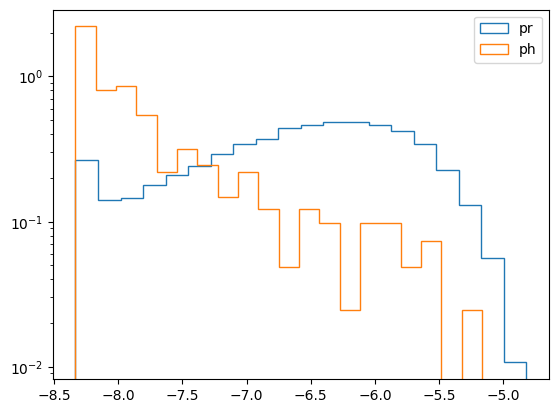

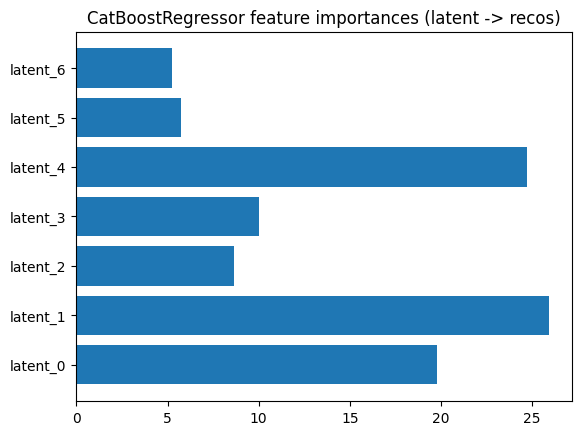

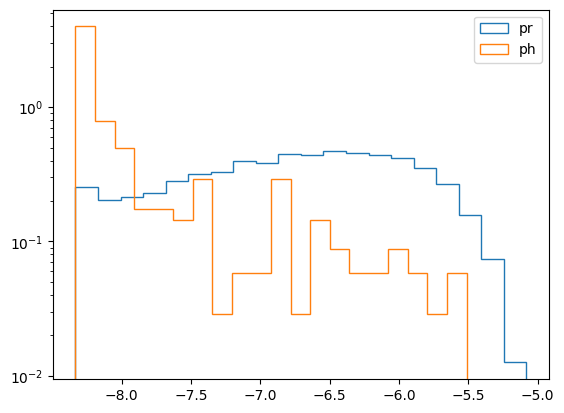

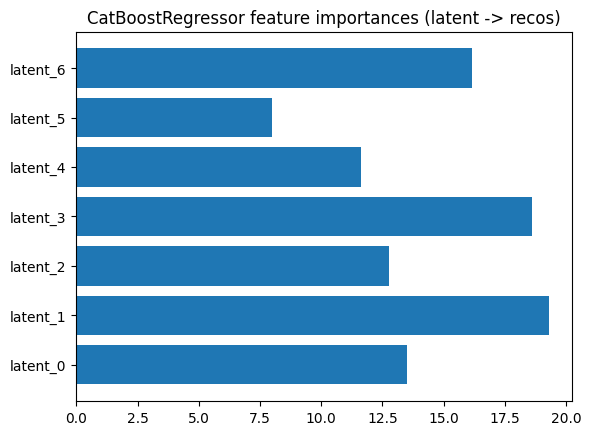

In [93]:
scores_pr_1, scores_ph_1, recos_pr_choise_1, recos_photon_choise_1, figs_1 = get_anomaly_score(path_save_1)
scores_pr_2, scores_ph_2, recos_pr_choise_2, recos_photon_choise_2, figs_2 = get_anomaly_score(path_save_2)

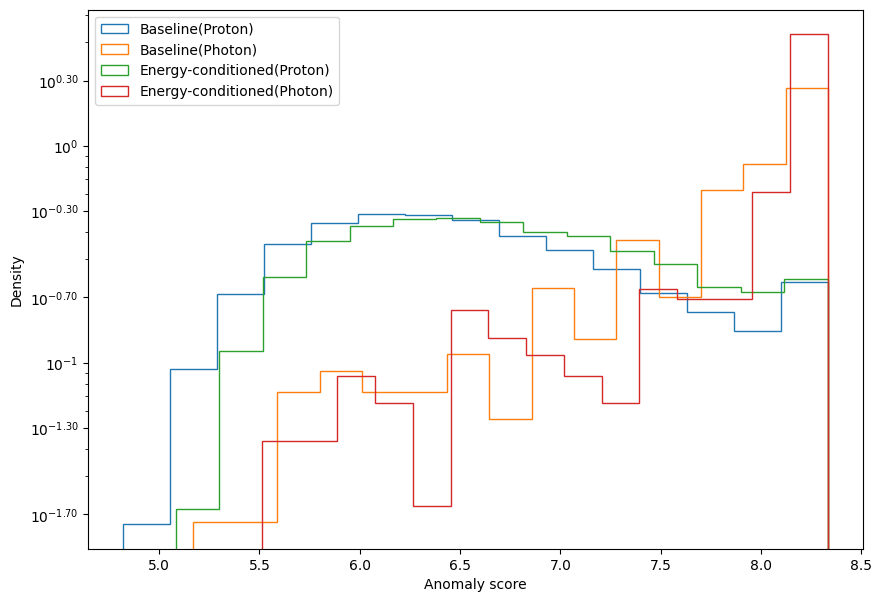

In [94]:
from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter


fig, ax = plt.subplots(figsize=(10, 7))
ax.hist(-scores_pr_1, bins=15, label='Baseline(Proton)', histtype='step', density=True, log=True)
ax.hist(-scores_ph_1, bins=15, label='Baseline(Photon)', histtype='step', density=True, log=True)
ax.hist(-scores_pr_2, bins=15, label='Energy-conditioned(Proton)', histtype='step', density=True, log=True)
ax.hist(-scores_ph_2, bins=15, label='Energy-conditioned(Photon)', histtype='step', density=True, log=True)
ax.set_xlabel('Anomaly score')
ax.set_ylabel('Density')
ax.legend()


ax.yaxis.set_major_locator(
    LogLocator(base=10, subs=(1.0, 2.0, 5.0), numticks=20)
)

ax.yaxis.set_major_formatter(
    LogFormatterMathtext(
        base=10,
        labelOnlyBase=False,
        minor_thresholds=(10, 10)
    )
)

# ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0), numticks=15))
# ax.yaxis.set_major_formatter(LogFormatterMathtext(labelOnlyBase=False))
# ax.yaxis.set_minor_formatter(NullFormatter())

# ax.yaxis.set_major_locator(LogLocator(base=10, numticks=12))
# ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10), numticks=12))
# ax.yaxis.set_minor_formatter(LogFormatterMathtext(labelOnlyBase=False))

In [95]:
def get_part_anomay(scores_pr_1, scores_ph_1, precentile = 0.85):
    scores = np.concatenate([scores_pr_1, scores_ph_1])
    threshold = np.percentile(scores, precentile)
    index = np.where(scores > threshold)[0]

    anomaly_ph = scores_ph_1>threshold
    anomaly_pr = scores_pr_1>threshold

    normal_ph = scores_ph_1<=threshold
    normal_pr = scores_pr_1<=threshold
    print('part ph on part pr', len(scores_ph_1), len(scores_pr_1), len(scores_ph_1)/len(scores_pr_1), precentile, threshold)
    print('PH: anomaly', anomaly_ph.sum(), 'normal', normal_ph.sum(), 'part', anomaly_ph.sum()/len(scores_ph_1))
    print('PR: anomaly', anomaly_pr.sum(), 'normal', normal_pr.sum(), 'part', anomaly_pr.sum()/len(scores_pr_1), '\n')
    return anomaly_ph, anomaly_pr, normal_ph, normal_pr

anomaly_ph, anomaly_pr, normal_ph, normal_pr = get_part_anomay(-scores_pr_1, -scores_ph_1, 0.85*100)

anomaly_ph, anomaly_pr, normal_ph, normal_pr = get_part_anomay(-scores_pr_2, -scores_ph_2, 0.85*100)



part ph on part pr 258 30327 0.00850727074883767 85.0 7.54595338331078
PH: anomaly 189 normal 69 part 0.7325581395348837
PR: anomaly 4399 normal 25928 part 0.14505226365944537 

part ph on part pr 244 30336 0.00804324894514768 85.0 7.691491288350267
PH: anomaly 192 normal 52 part 0.7868852459016393
PR: anomaly 4395 normal 25941 part 0.14487737341772153 



(8, 2) (8, 2) (8, 2)
(9, 2) (9, 2) (9, 2)
-2.1000821756187107
pr_anomaly 0.11597243971186971 ph_anomaly 0.574609375
ph/pr 0.08017538365173818


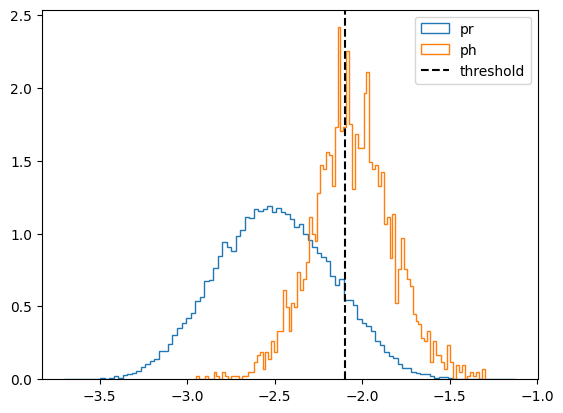

(8, 2) (8, 2) (8, 2)
(9, 2) (9, 2) (9, 2)
-2.1050382621630996
pr_anomaly 0.11352959599123082 ph_anomaly 0.605078125
ph/pr 0.08017538365173818


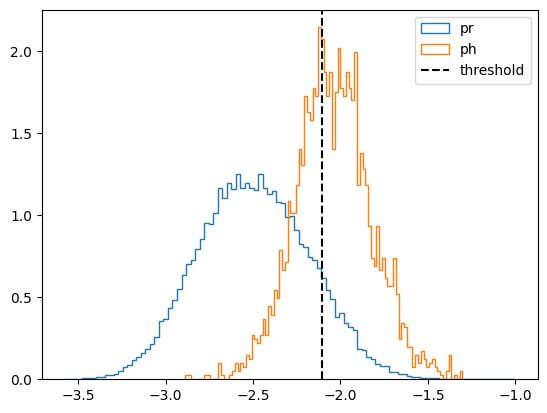

In [110]:
def los_hist(path_save, precentile = 0.85):
    reconstruction_data_pr = np.load(os.path.join(path_save, 'pr', 'reconstruction_data.npy'), allow_pickle=True)
    reconstruction_data_photon = np.load(os.path.join(path_save, 'photon', 'reconstruction_data.npy'), allow_pickle=True)

    num_det_pr = np.load(os.path.join(path_save, 'pr', 'num_det.npy'))
    num_det_photon = np.load(os.path.join(path_save, 'photon', 'num_det.npy'))

    dt_params_pr_signal = [d[:, 3:4] for d in dt_params_pr]
    dt_params_pr_time = [d[:, -1:] for d in dt_params_pr]
    dt_params_pr_signal_rubsov = [d[:, 3:4] for d in dt_params_rubsov_approximation_pr]
    dt_params_pr_time_rubsov = [d[:, -1:] for d in dt_params_rubsov_approximation_pr]
    dt_params_pr_signal_model = [d[:, 3:4] for d in reconstruction_data_pr]
    dt_params_pr_time_model = [d[:, 4:] for d in reconstruction_data_pr]

    dt_params_pr_sig_time = [np.concatenate([dt_params_pr_signal[i], dt_params_pr_time[i]], axis=1) for i in range(len(dt_params_pr_signal))]
    dt_params_pr_sig_time_rubsov = [np.concatenate([dt_params_pr_signal_rubsov[i], dt_params_pr_time_rubsov[i]], axis=1) for i in range(len(dt_params_pr_signal_rubsov))]
    dt_params_pr_sig_time_model = [np.concatenate([dt_params_pr_signal_model[i], dt_params_pr_time_model[i]], axis=1) for i in range(len(dt_params_pr_signal_model))]
    print(dt_params_pr_sig_time[0].shape, dt_params_pr_sig_time_rubsov[0].shape, dt_params_pr_sig_time_model[0].shape)

    dt_params_ph_signal = [d[:, 3:4] for d in dt_params_ph]
    dt_params_ph_time = [d[:, -1:] for d in dt_params_ph]
    dt_params_ph_signal_rubsov = [d[:, 3:4] for d in dt_params_rubsov_approximation_ph]
    dt_params_ph_time_rubsov = [d[:, -1:] for d in dt_params_rubsov_approximation_ph]
    dt_params_ph_signal_model = [d[:, 3:4] for d in reconstruction_data_photon]
    dt_params_ph_time_model = [d[:, 4:] for d in reconstruction_data_photon]

    dt_params_ph_sig_time = [np.concatenate([dt_params_ph_signal[i], dt_params_ph_time[i]], axis=1) for i in range(len(dt_params_ph_signal))]
    dt_params_ph_sig_time_rubsov = [np.concatenate([dt_params_ph_signal_rubsov[i], dt_params_ph_time_rubsov[i]], axis=1) for i in range(len(dt_params_ph_signal_rubsov))]
    dt_params_ph_sig_time_model = [np.concatenate([dt_params_ph_signal_model[i], dt_params_ph_time_model[i]], axis=1) for i in range(len(dt_params_ph_signal_model))]
    print(dt_params_ph_sig_time[0].shape, dt_params_ph_sig_time_rubsov[0].shape, dt_params_ph_sig_time_model[0].shape)

    embading_pr = np.load(os.path.join(path_save, 'pr', 'embading.npy'))
    embading_photon = np.load(os.path.join(path_save, 'photon', 'embading.npy'))
    recos_pr = np.load(os.path.join(path_save, 'pr', 'recos.npy'))
    recos_photon = np.load(os.path.join(path_save, 'photon', 'recos.npy'))
    recon_loss_pr = np.load(os.path.join(path_save, 'pr', 'recon_loss.npy'))
    recon_loss_photon = np.load(os.path.join(path_save, 'photon', 'recon_loss.npy'))

    num = 20000
    num_ph = 200
    N = 16
    NUM_STEP = 3


    index_det = (N <= num_det_pr) * (num_det_pr < N + NUM_STEP)
    embading_pr = embading_pr[index_det]
    num_det_pr = num_det_pr[index_det]

    recon_loss_pr = recon_loss_pr[index_det]
    index_ph = (N <= num_det_photon) * (num_det_photon < N + NUM_STEP)
    embading_photon = embading_photon[index_ph]
    num_det_photon = num_det_photon[index_ph]
    recon_loss_photon = recon_loss_photon[index_ph]
    index = np.random.choice(len(embading_pr), num, replace=False)
    index_ph = np.random.choice(len(embading_photon), num_ph, replace=False)

    recos_pr = recos_pr[index]
    recos_photon = recos_photon[index_ph]

    plt.hist(np.log10(recon_loss_pr), bins=100, label='pr', histtype='step', density=True)
    plt.hist(np.log10(recon_loss_photon), bins=100, label='ph', histtype='step', density=True)
    
    th = np.percentile(np.concatenate([np.log10(recon_loss_pr), np.log10(recon_loss_photon)]), precentile)
    print(th)
    plt.axvline(th, color='k', linestyle='--', label='threshold')

    pr_anomaly = np.log10(recon_loss_pr)>th
    ph_anomaly = np.log10(recon_loss_photon)>th
    print('pr_anomaly', pr_anomaly.sum()/len(recon_loss_pr), 'ph_anomaly', ph_anomaly.sum()/len(recon_loss_photon))
    print('ph/pr', len(recon_loss_photon)/len(recon_loss_pr))
    plt.legend()
    plt.show()

los_hist(path_save_1, 85)
los_hist(path_save_2, 85)

In [60]:
def get_part_anomay_threshold(scores_pr_1, scores_ph_1, threshold = 0.85):
    scores = np.concatenate([scores_pr_1, scores_ph_1])
    # threshold = np.percentile(scores, precentile)
    index = np.where(scores > threshold)[0]

    anomaly_ph = scores_ph_1>threshold
    anomaly_pr = scores_pr_1>threshold

    normal_ph = scores_ph_1<=threshold
    normal_pr = scores_pr_1<=threshold
    print('part ph on part pr', len(scores_ph_1)/len(scores_pr_1), threshold)
    print('PH: anomaly', anomaly_ph.sum(), 'normal', normal_ph.sum(), 'part', anomaly_ph.sum()/len(scores_ph_1))
    print('PR: anomaly', anomaly_pr.sum(), 'normal', normal_pr.sum(), 'part', anomaly_pr.sum()/len(scores_pr_1), '\n')
    return anomaly_ph, anomaly_pr, normal_ph, normal_pr

anomaly_ph, anomaly_pr, normal_ph, normal_pr = get_part_anomay_threshold(-scores_pr_1, -scores_ph_1, threshold = 6.62)

anomaly_ph, anomaly_pr, normal_ph, normal_pr = get_part_anomay_threshold(-scores_pr_2, -scores_ph_2, threshold = 6.62)

part ph on part pr 0.005273131745900964 6.62
PH: anomaly 20 normal 44 part 0.3125
PR: anomaly 2258 normal 9879 part 0.18604267941006838 

part ph on part pr 0.0045995893223819305 6.62
PH: anomaly 33 normal 23 part 0.5892857142857143
PR: anomaly 3019 normal 9156 part 0.24796714579055443 



In [100]:
# bin by np.log10(E), E = rec * std + mean + 18.5
def bin_by_log10(rec, n_bins=15):
    rec_pr_norm = rec * std_recos[3] + mean_recos[3]
    log_rec = np.log10(rec_pr_norm) + 18
    bins = np.linspace(log_rec.min(), log_rec.max(), n_bins)
    indexes = []
    mean_bins = []
    for i in range(len(bins) - 1):
        index = np.where((log_rec >= bins[i]) & (log_rec < bins[i + 1]))[0]
        indexes.append(index)
        mean_bins.append((bins[i] + bins[i + 1]) / 2)
    return indexes, mean_bins


def plot_anomaly_score(anomaly_score, rec):
    indexes, mean_bins = bin_by_log10(rec)
    mean_anomaly_score = []
    std_anomaly_score = []
    mean_bins_used = []

    for index, mean_bin in zip(indexes, mean_bins):
        if len(index) == 0:
            continue
        scores_bin = anomaly_score[index]
        mean_bins_used.append(mean_bin)
        mean_anomaly_score.append(scores_bin.mean())
        std_anomaly_score.append(scores_bin.std())

    return mean_bins_used, mean_anomaly_score, std_anomaly_score


mean_recos_1, mean_anomaly_score_1, std_anomaly_score_1 = plot_anomaly_score(scores_pr_1, rec_pr)
mean_recos_2, mean_anomaly_score_2, std_anomaly_score_2 = plot_anomaly_score(scores_pr_2, rec_pr_2)








[18.739363465990337, 18.905315739767893, 19.071268013545442, 19.237220287322998, 19.403172561100554, 19.569124834878103, 19.73507710865566, 19.901029382433208, 20.066981656210764, 20.232933929988313, 20.39888620376587, 20.564838477543425, 20.730790751320974, 20.89674302509853] [-8.321819580855763, -8.123734016880638, -7.833790826966166, -7.601323952664252, -7.270153564045225, -6.918257000058814, -6.616065173843116, -6.473423828775199, -6.424755266060141, -6.483047774578916, -6.638518708385875, -6.931456190738489, -7.218094797982409, -7.765350667314681] [0.0011531500316088739, 0.20009917883345024, 0.5125671175921914, 0.49996655078816216, 0.6074991041253549, 0.6943308951186641, 0.7397935633004201, 0.767832509552861, 0.7811800751388279, 0.8044401125337233, 0.8223846734152994, 0.7672450213312431, 0.7450733055725027, 0.5530874522735513]


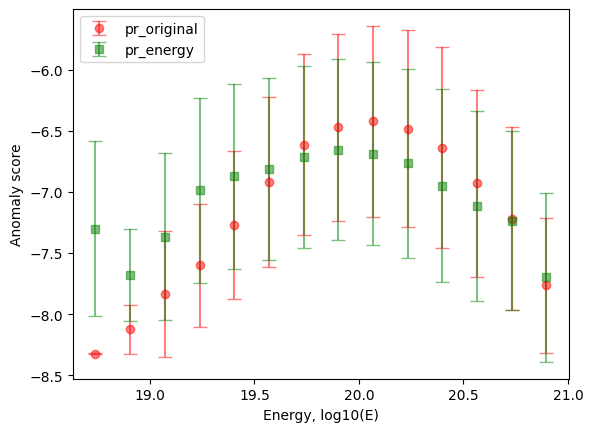

In [101]:
print(mean_recos_1, mean_anomaly_score_1, std_anomaly_score_1)
names_datasets = ['pr_original', 'pr_energy']
colors = ['r', 'g', 'b']
simbols = ['o', 's', 'D']
        # ax[i].errorbar(num_det_list, mean_lists[:,i], yerr=std_lists[:,i],
        #                marker=simbols[d], color=colors[d], linestyle='none',capsize = 5, label=names_datasets[d])
plt.errorbar(mean_recos_1, mean_anomaly_score_1, yerr=std_anomaly_score_1, alpha=0.5,
            marker=simbols[0], color=colors[0], linestyle='none',capsize = 5, label=names_datasets[0])
plt.errorbar(mean_recos_2, mean_anomaly_score_2, yerr=std_anomaly_score_2, alpha=0.5,
            marker=simbols[1], color=colors[1], linestyle='none',capsize = 5, label=names_datasets[1])
plt.legend()
plt.xlabel('Energy, log10(E)')
plt.ylabel('Anomaly score')
plt.show()




<Figure size 1000x700 with 0 Axes>

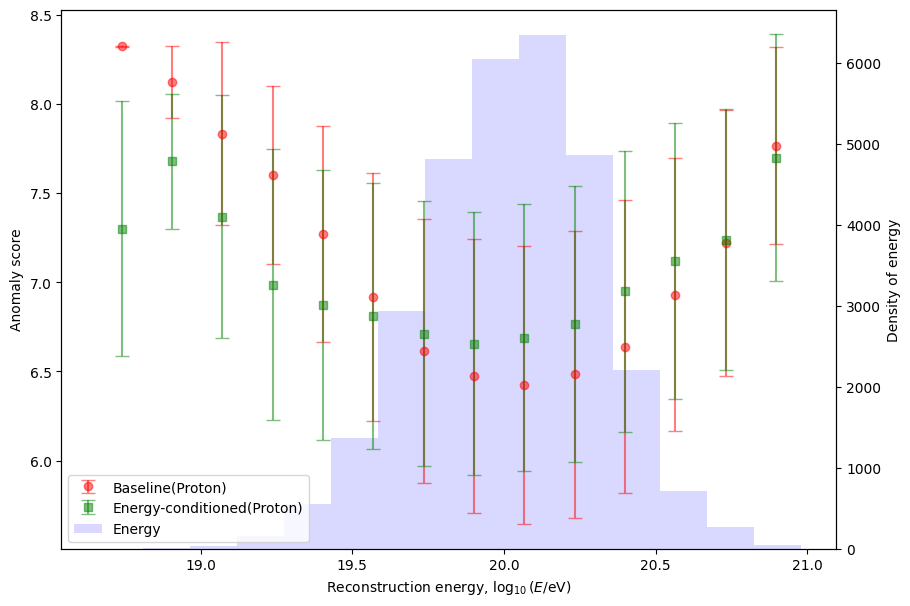

In [102]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10,7))
names_datasets = ['Baseline(Proton)', 'Energy-conditioned(Proton)']
colors = ['r', 'g', 'b']
simbols = ['o', 's', 'D']

fig, ax = plt.subplots(figsize=(10, 7))

ax.errorbar(mean_recos_1, -np.array(mean_anomaly_score_1), yerr=std_anomaly_score_1, alpha=0.5,
            marker=simbols[0], color=colors[0], linestyle='none', capsize=5,
            label=names_datasets[0], zorder=3)
ax.errorbar(mean_recos_2, -np.array(mean_anomaly_score_2), yerr=std_anomaly_score_2, alpha=0.5,
            marker=simbols[1], color=colors[1], linestyle='none', capsize=5,
            label=names_datasets[1], zorder=3)

ax.set_xlabel(r'Reconstruction energy, $\log_{10}(E/\mathrm{eV})$')
ax.set_ylabel('Anomaly score')

# вторая ось Y для гистограммы
ax2 = ax.twinx()
ax2.hist(np.log10(rec_pr_norm) + 18, bins=15, color=colors[2], alpha=0.15, label='Energy')
ax2.set_ylabel('Density of energy')

# чтобы errorbar рисовался поверх гистограммы
ax.set_zorder(ax2.get_zorder() + 1)
ax.patch.set_visible(False)

# общая легенда
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2)

plt.show()

[18.95494318008423, 19.072383403778076, 19.189823627471924, 19.30726385116577, 19.42470407485962, 19.542144298553467, 19.659584522247314, 19.777024745941162, 19.89446496963501, 20.011905193328857, 20.129345417022705, 20.246785640716553, 20.3642258644104, 20.481666088104248] [-8.950768550835894, -7.551303613597752, -8.305751500191432, -8.304509353266658, -7.777978615368514, -7.387499958455113, -7.128559442300952, -6.7184541066608805, -6.3882627575806925, -6.340040167040151, -6.344984876354379, -6.251663561807497, -6.718924459223245, -6.233685620746416] [0.0, 0.0, 0.0, 0.6059738160889382, 0.7836391355484185, 0.9344289678019055, 0.9280693273401264, 0.9925327129405925, 0.973940280419107, 1.151115005044029, 1.244681027362941, 1.2733360814349082, 1.6059256863265055, 1.2196138487607269]


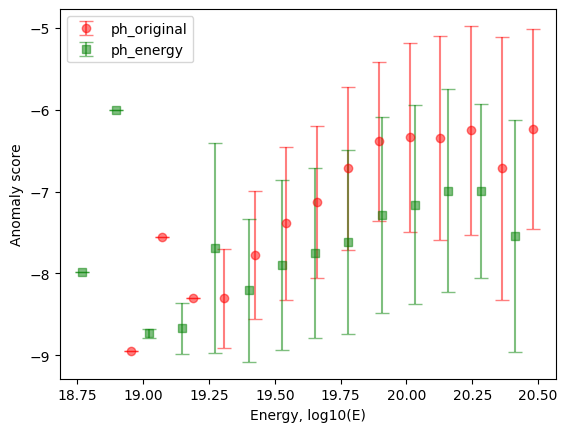

In [20]:

mean_recos_1, mean_anomaly_score_1, std_anomaly_score_1 = plot_anomaly_score(scores_ph_1, rec_ph)
mean_recos_2, mean_anomaly_score_2, std_anomaly_score_2 = plot_anomaly_score(scores_ph_2, rec_ph_2)

print(mean_recos_1, mean_anomaly_score_1, std_anomaly_score_1)
names_datasets = ['ph_original', 'ph_energy']
colors = ['r', 'g', 'b']
simbols = ['o', 's', 'D']
        # ax[i].errorbar(num_det_list, mean_lists[:,i], yerr=std_lists[:,i],
        #                marker=simbols[d], color=colors[d], linestyle='none',capsize = 5, label=names_datasets[d])
plt.errorbar(mean_recos_1, mean_anomaly_score_1, yerr=std_anomaly_score_1, alpha=0.5,
            marker=simbols[0], color=colors[0], linestyle='none',capsize = 5, label=names_datasets[0])
plt.errorbar(mean_recos_2, mean_anomaly_score_2, yerr=std_anomaly_score_2, alpha=0.5,
            marker=simbols[1], color=colors[1], linestyle='none',capsize = 5, label=names_datasets[1])
plt.legend()
plt.xlabel('Energy, log10(E)')
plt.ylabel('Anomaly score')
plt.show()

In [21]:
def bin_by_log10_eq_in_interval(rec, n_bins=15):
    rec_pr_norm = rec * std_recos[3] + mean_recos[3] + 18.5
    log_rec = np.log10(rec_pr_norm) + 16.5

    bins = np.linspace(log_rec.min(), log_rec.max(), n_bins)
    indexes = []
    mean_bins = []
    for i in range(len(bins) - 1):
        index = np.where((log_rec >= bins[i]) & (log_rec < bins[i + 1]))[0]
        indexes.append(index)
        mean_bins.append((bins[i] + bins[i + 1]) / 2)
    return indexes, mean_bins


def plot_anomaly_score(anomaly_score, rec):
    indexes, mean_bins = bin_by_log10(rec)
    mean_anomaly_score = []
    std_anomaly_score = []
    mean_bins_used = []

    for index, mean_bin in zip(indexes, mean_bins):
        if len(index) == 0:
            continue
        scores_bin = anomaly_score[index]
        mean_bins_used.append(mean_bin)
        mean_anomaly_score.append(scores_bin.mean())
        std_anomaly_score.append(scores_bin.std())

    return mean_bins_used, mean_anomaly_score, std_anomaly_score


In [22]:
# Corelation

import scipy.stats

Pearson_1 = scipy.stats.pearsonr(rec_pr, scores_pr_1)    # Pearson's r
Spearman_1 = scipy.stats.spearmanr(rec_pr, scores_pr_1)   # Spearman's rho
Kendall_1 = scipy.stats.kendalltau(rec_pr, scores_pr_1)  # Kendall's tau

Pearson_2 = scipy.stats.pearsonr(rec_pr_2, scores_pr_2)    # Pearson's r
Spearman_2 = scipy.stats.spearmanr(rec_pr_2, scores_pr_2)   # Spearman's rho
Kendall_2 = scipy.stats.kendalltau(rec_pr_2, scores_pr_2)  # Kendall's tau

print('Oringinal VAE  ',Pearson_1, Spearman_1, Kendall_1)
print('VAE with energy',Pearson_2, Spearman_2, Kendall_2)



Oringinal VAE   PearsonRResult(statistic=0.28174872301572035, pvalue=0.0) SignificanceResult(statistic=0.429302560838652, pvalue=0.0) SignificanceResult(statistic=0.30325971061827034, pvalue=0.0)
VAE with energy PearsonRResult(statistic=0.08629743343907752, pvalue=6.501680971411047e-80) SignificanceResult(statistic=0.14728465856808381, pvalue=1.257112726989568e-230) SignificanceResult(statistic=0.0990173632449416, pvalue=5.8354681846116245e-232)


In [18]:
reconstruction_data_pr = np.load(os.path.join(path_save, 'pr', 'reconstruction_data.npy'), allow_pickle = True)
reconstruction_data_photon = np.load(os.path.join(path_save, 'photon', 'reconstruction_data.npy'), allow_pickle = True)
reconstruction_data_pr.shape, reconstruction_data_photon.shape, reconstruction_data_pr[5].shape


((210315,), (210851,), (10, 5))

In [19]:
print(len(dt_params_pr), len(dt_params_ph), len(dt_params_rubsov_approximation_pr), len(dt_params_rubsov_approximation_ph))


210315 210851 210315 210851


In [20]:
dt_params_pr_signal = [d[:,3:4] for d in dt_params_pr]
dt_params_pr_time = [d[:,-1:] for d in dt_params_pr]
dt_params_pr_signal_rubsov = [d[:,3:4] for d in dt_params_rubsov_approximation_pr]
dt_params_pr_time_rubsov = [d[:,-1:] for d in dt_params_rubsov_approximation_pr]
dt_params_pr_signal_model = [d[:,3:4] for d in reconstruction_data_pr]
dt_params_pr_time_model = [d[:,4:] for d in reconstruction_data_pr]

dt_params_pr_sig_time = [np.concatenate([dt_params_pr_signal[i], dt_params_pr_time[i]], axis=1) for i in range(len(dt_params_pr_signal))]
dt_params_pr_sig_time_rubsov = [np.concatenate([dt_params_pr_signal_rubsov[i], dt_params_pr_time_rubsov[i]], axis=1) for i in range(len(dt_params_pr_signal_rubsov))]
dt_params_pr_sig_time_model = [np.concatenate([dt_params_pr_signal_model[i], dt_params_pr_time_model[i]], axis=1) for i in range(len(dt_params_pr_signal_model))]
print(dt_params_pr_sig_time[0].shape, dt_params_pr_sig_time_rubsov[0].shape, dt_params_pr_sig_time_model[0].shape)







(8, 2) (8, 2) (8, 2)


In [21]:
dt_params_ph_signal = [d[:,3:4] for d in dt_params_ph]
dt_params_ph_time = [d[:,-1:] for d in dt_params_ph]
dt_params_ph_signal_rubsov = [d[:,3:4] for d in dt_params_rubsov_approximation_ph]
dt_params_ph_time_rubsov = [d[:,-1:] for d in dt_params_rubsov_approximation_ph]
dt_params_ph_signal_model = [d[:,3:4] for d in reconstruction_data_photon]
dt_params_ph_time_model = [d[:,4:] for d in reconstruction_data_photon]

dt_params_ph_sig_time = [np.concatenate([dt_params_ph_signal[i], dt_params_ph_time[i]], axis=1) for i in range(len(dt_params_ph_signal))]
dt_params_ph_sig_time_rubsov = [np.concatenate([dt_params_ph_signal_rubsov[i], dt_params_ph_time_rubsov[i]], axis=1) for i in range(len(dt_params_ph_signal_rubsov))]
dt_params_ph_sig_time_model = [np.concatenate([dt_params_ph_signal_model[i], dt_params_ph_time_model[i]], axis=1) for i in range(len(dt_params_ph_signal_model))]
print(dt_params_ph_sig_time[0].shape, dt_params_ph_sig_time_rubsov[0].shape, dt_params_ph_sig_time_model[0].shape)





(9, 2) (9, 2) (9, 2)


In [22]:
num_det_pr = np.load(os.path.join(path_save, 'pr', 'num_det.npy'))
num_det_photon = np.load(os.path.join(path_save, 'photon', 'num_det.npy'))
num_det_pr.shape, num_det_photon.shape, num_det_pr[:20]

((210315,),
 (210851,),
 array([ 8.,  9., 15.,  9., 13., 10.,  7.,  7.,  9., 11., 12., 19., 10.,
        13., 12.,  7., 12., 12.,  8., 17.]))

In [23]:
recon_loss_pr = np.load(os.path.join(path_save, 'pr', 'recon_loss.npy'))
recon_loss_photon = np.load(os.path.join(path_save, 'photon', 'recon_loss.npy'))
recon_loss_pr.shape, recon_loss_photon.shape, recon_loss_pr[:20]

((210315,),
 (210851,),
 array([0.00090569, 0.00033525, 0.00073619, 0.00090685, 0.00071722,
        0.00678441, 0.00257892, 0.00264535, 0.00052548, 0.00832866,
        0.0045163 , 0.00157081, 0.00207382, 0.00443368, 0.00314934,
        0.00066368, 0.00166019, 0.00370934, 0.00127994, 0.0012819 ]))

In [24]:
embading_pr = np.load(os.path.join(path_save, 'pr', 'embading.npy'))
embading_photon = np.load(os.path.join(path_save, 'photon', 'embading.npy'))
recos_pr = np.load(os.path.join(path_save, 'pr', 'recos.npy'))
recos_photon = np.load(os.path.join(path_save, 'photon', 'recos.npy'))

recos_norming_pr = recos_pr * std_recos + mean_recos
recos_norming_photon = recos_photon * std_recos + mean_recos

embading_pr.shape, embading_photon.shape, recos_pr.shape,




((210315, 6), (210851, 6), (210315, 15))

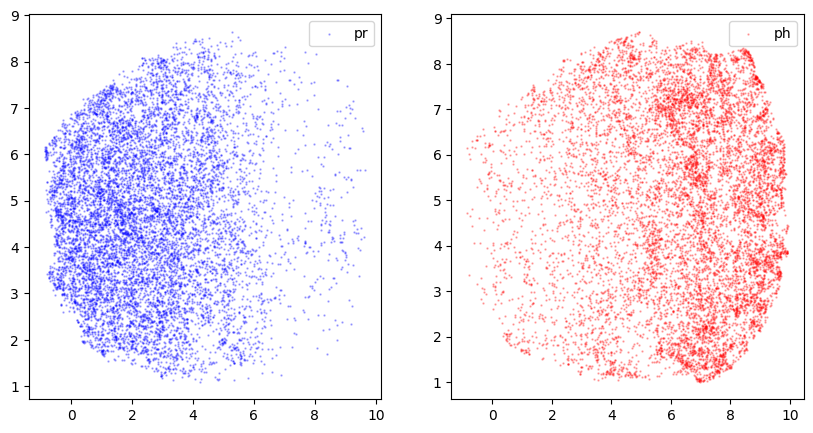

In [25]:
#UMAP
N=10000
reducer = umap.UMAP(n_components=2)
manifold = reducer.fit(np.concatenate([embading_pr[:N], embading_photon[:N]], axis=0))
X_umap = manifold.transform(np.concatenate([embading_pr[:N], embading_photon[:N]], axis=0))
X_pr_umap = X_umap[:len(embading_pr[:N])]
X_ph_umap = X_umap[len(embading_pr[:N]):]

fig,axs = plt.subplots(1,2, figsize=(10,5))
axs[0].scatter(X_pr_umap[:,0], X_pr_umap[:,1], s=0.5, color='blue', alpha=0.3, label='pr')
axs[1].scatter(X_ph_umap[:,0], X_ph_umap[:,1], s=0.5, color='red', alpha=0.3, label='ph')
axs[0].legend()
axs[1].legend()
plt.show()





In [26]:
N=13
NUM_STEP=3
index_pr_N_det = np.where((N<=num_det_pr)*(num_det_pr<N+NUM_STEP))[0]
index_ph_N_det = np.where((N<=num_det_photon)*(num_det_photon<N+NUM_STEP))[0]

emeding_pr_per_NUM_DET = embading_pr[index_pr_N_det]
emeding_ph_per_NUM_DET = embading_photon[index_ph_N_det]
print(emeding_pr_per_NUM_DET.shape,emeding_ph_per_NUM_DET.shape)

(50466, 6) (13581, 6)


(50466,) (13581,)


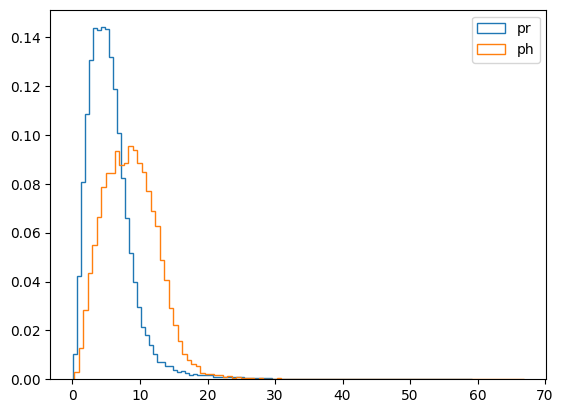

In [27]:
rudius_pr = np.sum(emeding_pr_per_NUM_DET**2, axis=1)
radius_ph = np.sum(emeding_ph_per_NUM_DET**2, axis=1)
print(rudius_pr.shape, radius_ph.shape)

plt.hist(rudius_pr,density=True, bins=100, label='pr', histtype='step', )
plt.hist(radius_ph,density=True, bins=100, label='ph', histtype='step', )
plt.legend()


    recos (num_evs,15):
    0. theta
    1. phi
    2. S_800
    3. E_gamma
    4. d_border, km
    5. chi2/ndof for joint fit
    6. Linsley front curvature
    7. Area-over-peak (AOP) 1200
    8. AOP slope
    9. S_b parameter, b=2.5 (arXiv:1104.3399, arXiv:1305.7439)
    10. S_b parameter, b=4.0
    11. sum of all signals in all detectors
    12. asymmetry  of  the  summed signal  at  the  upper  and  lower layers of detectors
    13. total number of peaks in event
    14. number of peaks for the detector with the largest signal

In [28]:
name_recos = ['theta', 'phi', 'S_800', 'E_gamma', 'd_border', 'chi2/ndof', 'Linsley front curvature', 'Area-over-peak (AOP) 1200', 'AOP slope', 'S_b parameter, b=2.5', 'S_b parameter, b=4.0', 'sum of all signals in all detectors', 'asymmetry  of  the  summed signal  at  the  upper  and  lower layers of detectors', 'total number of peaks in event', 'number of peaks for the detector with the largest signal']

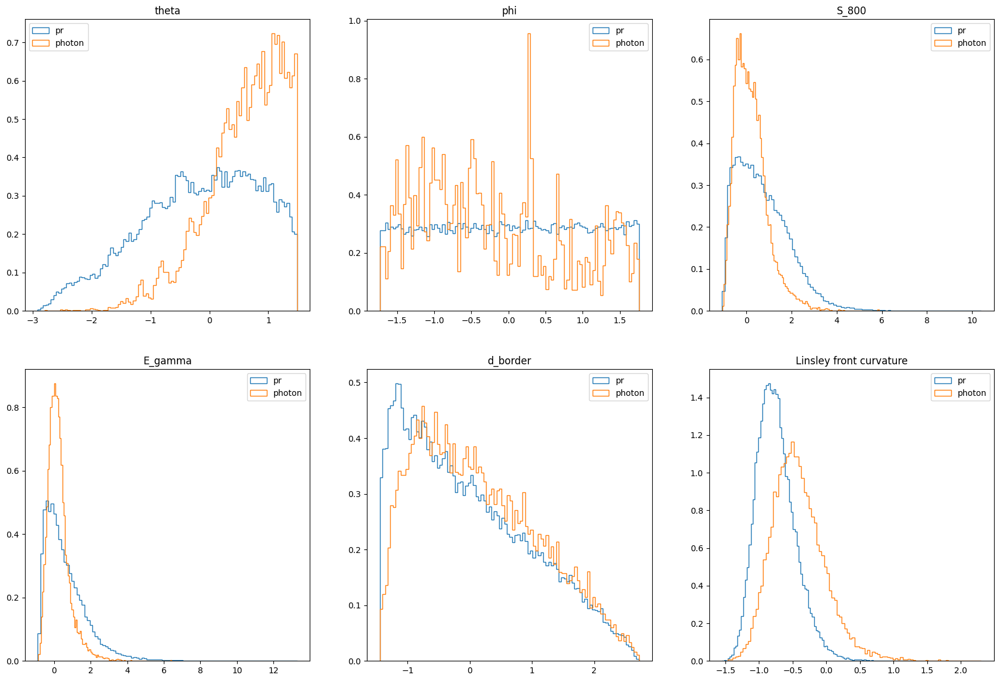

(50466, 15) (13581, 15)
(504, 15) (50466, 15)
(50970, 15) (50970,)


In [ ]:

part_ph=0.01
recos_const_num_det_pr = recos_pr[index_pr_N_det]
recos_const_num_det_photon = recos_photon[index_ph_N_det]
fig, ax = plt.subplots(2,3, figsize=(21, 14))
index = [0,1,2,3,4,6]
for i, id_ in enumerate(index):

    ax[i//3,i%3].hist(recos_const_num_det_pr[:,id_], bins=100, label='pr', histtype='step', density=True)
    ax[i//3,i%3].hist(recos_const_num_det_photon[:,id_], bins=100, label='photon', histtype='step', density=True)
    ax[i//3,i%3].legend()
    ax[i//3,i%3].set_title(f'{name_recos[id_]}')
plt.show()
num_recos = recos_pr.shape[1]
print(recos_const_num_det_pr.shape, recos_const_num_det_photon.shape)
NUM_PH = int(part_ph*len(recos_const_num_det_pr))
index_ph = np.random.randint(0, len(recos_const_num_det_photon), NUM_PH)
recos_const_num_det_photon = recos_const_num_det_photon[index_ph]
print(recos_const_num_det_photon.shape, recos_const_num_det_pr.shape)

# shufle 

label_pr = np.zeros(len(recos_const_num_det_pr))
label_ph = np.ones(len(recos_const_num_det_photon))
recos_const_num_det = np.concatenate([recos_const_num_det_pr, recos_const_num_det_photon], axis=0)
label = np.concatenate([label_pr, label_ph], axis=0)

shufle_index = np.random.permutation(len(recos_const_num_det))
recos_const_num_det = recos_const_num_det[shufle_index]
label = label[shufle_index]


print(recos_const_num_det.shape, label.shape)






 # ЧТО СДЕЛАТЬ НА 06.07

 + Добавить reocs [0,1,2]  theta. phi. S800

 + Убрать фотоны из обучающего




In [30]:
# classification catboost
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score
from sklearn.metrics import confusion_matrix
# index_recos = [0,1,2,6]
index_recos = list(np.arange(15))
recos_all = np.concatenate([recos_pr, recos_photon], axis=0)[:,index_recos]
label_all = np.concatenate([np.zeros(len(recos_pr)), np.ones(len(recos_photon))], axis=0)

X_train, X_test, y_train, y_test = train_test_split(recos_all, label_all, test_size=0.2, random_state=42)
model = CatBoostClassifier(n_estimators=1000, depth=4, learning_rate=0.1, random_state=42)
model.fit(X_train, y_train)
predict = model.predict(X_test)
score = model.predict_proba(X_test)[:,1]

roc_auc = roc_auc_score(y_test, score)
f1 = f1_score(y_test, predict)
precision = precision_score(y_test, predict)
recall = recall_score(y_test, predict)
cm = confusion_matrix(y_test, predict)
print(f'roc_auc: {roc_auc}, f1: {f1}, precision: {precision}, recall: {recall}')
print(cm)



0:	learn: 0.6391523	total: 73.9ms	remaining: 1m 13s
1:	learn: 0.5963438	total: 93.1ms	remaining: 46.4s
2:	learn: 0.5628390	total: 110ms	remaining: 36.6s
3:	learn: 0.5359366	total: 128ms	remaining: 31.8s
4:	learn: 0.5127903	total: 144ms	remaining: 28.6s
5:	learn: 0.4948665	total: 160ms	remaining: 26.5s
6:	learn: 0.4795833	total: 176ms	remaining: 24.9s
7:	learn: 0.4669513	total: 192ms	remaining: 23.8s
8:	learn: 0.4557026	total: 207ms	remaining: 22.8s
9:	learn: 0.4466296	total: 221ms	remaining: 21.9s
10:	learn: 0.4389196	total: 237ms	remaining: 21.3s
11:	learn: 0.4311491	total: 252ms	remaining: 20.8s
12:	learn: 0.4248207	total: 267ms	remaining: 20.2s
13:	learn: 0.4186357	total: 284ms	remaining: 20s
14:	learn: 0.4139977	total: 299ms	remaining: 19.6s
15:	learn: 0.4092954	total: 314ms	remaining: 19.3s
16:	learn: 0.4037468	total: 329ms	remaining: 19s
17:	learn: 0.3997141	total: 346ms	remaining: 18.9s
18:	learn: 0.3961360	total: 361ms	remaining: 18.7s
19:	learn: 0.3920718	total: 379ms	remainin

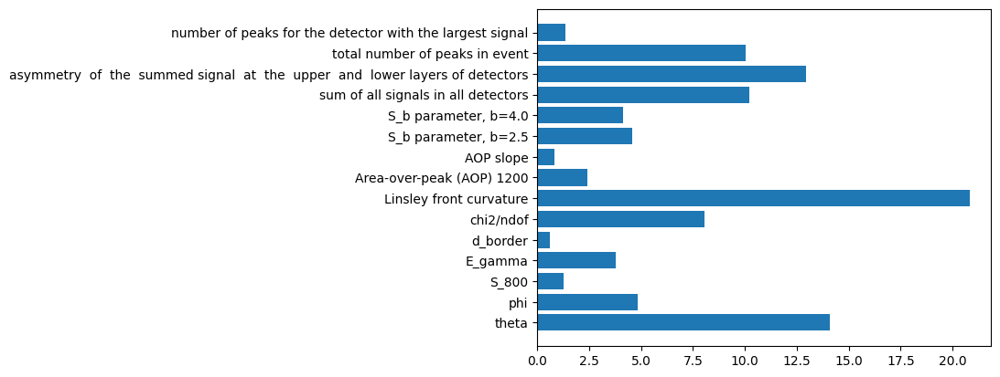

[14.06946831  4.82904991  1.27747189  3.78636931  0.61130988  8.07601845
 20.81526826  2.3951434   0.83985966  4.58928294  4.12720777 10.22857937
 12.96617183 10.01950979  1.36928922]


In [31]:
plt.barh([name_recos[i] for i in index_recos],model.feature_importances_,)
plt.show()
print(model.feature_importances_,)

In [32]:
from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Обучаем CatBoost на отдельные целевые переменные, например, только на theta, phi, S800
# Предполагаем, что recos_pr имеет shape (N_samples, N_features)
# Выберем индексы признаков и целевых переменных
index_recos = [0, 1, 2, 3, 4, 6]  # theta, phi, S800

latent_pr = embading_pr
label_all = recos_pr[:, index_recos]  # только эти три параметры

# Мульти-таргет регрессия: нужно использовать отдельный CatBoostRegressor для каждого параметра
X_train, X_test, y_train, y_test = train_test_split(latent_pr, label_all, test_size=0.2, random_state=42)

models = []
preds = []
metrics = []
target_names = ['theta', 'phi', 'S800', 'E_gamma', 'd_border', 'Linsley front curvature']
for i in range(label_all.shape[1]):
    model = CatBoostRegressor(n_estimators=1000, depth=4, learning_rate=0.1, random_state=42, verbose=0)
    model.fit(X_train, y_train[:, i])
    y_pred = model.predict(X_test)
    models.append(model)
    preds.append(y_pred)
    mse = mean_squared_error(y_test[:, i], y_pred)
    mae = mean_absolute_error(y_test[:, i], y_pred)
    r2 = r2_score(y_test[:, i], y_pred)
    metrics.append((mse, mae, r2))
    print(f'[{target_names[i]}] MSE: {mse:.5f}, MAE: {mae:.5f}, R2: {r2:.5f}')

# preds[0], preds[1], preds[2] - предсказания по theta, phi, S800


[theta] MSE: 0.09917, MAE: 0.23773, R2: 0.91121
[phi] MSE: 0.26101, MAE: 0.30233, R2: 0.74462
[S800] MSE: 0.08761, MAE: 0.19101, R2: 0.93746
[E_gamma] MSE: 0.15587, MAE: 0.23240, R2: 0.89525
[d_border] MSE: 1.00396, MAE: 0.84082, R2: -0.00245
[Linsley front curvature] MSE: 0.10650, MAE: 0.23447, R2: 0.67696


In [33]:
latent_pr = embading_photon
label_all = recos_photon[:, index_recos]  # только эти три параметры

# Мульти-таргет регрессия: нужно использовать отдельный CatBoostRegressor для каждого параметра
X_train, X_test, y_train, y_test = train_test_split(latent_pr, label_all, test_size=0.2, random_state=42)

models = []
preds = []
metrics = []
target_names = ['theta', 'phi', 'S800', 'E_gamma', 'd_border', 'Linsley front curvature']
for i in range(label_all.shape[1]):
    model = CatBoostRegressor(n_estimators=1000, depth=4, learning_rate=0.1, random_state=42, verbose=0)
    model.fit(X_train, y_train[:, i])
    y_pred = model.predict(X_test)
    models.append(model)
    preds.append(y_pred)
    mse = mean_squared_error(y_test[:, i], y_pred)
    mae = mean_absolute_error(y_test[:, i], y_pred)
    r2 = r2_score(y_test[:, i], y_pred)
    metrics.append((mse, mae, r2))
    print(f'[{target_names[i]}] MSE: {mse:.5f}, MAE: {mae:.5f}, R2: {r2:.5f}')

# preds[0], preds[1], preds[2] - предсказания по theta, phi, S800

[theta] MSE: 0.08377, MAE: 0.21378, R2: 0.89772
[phi] MSE: 0.19371, MAE: 0.23322, R2: 0.80356
[S800] MSE: 0.02932, MAE: 0.10945, R2: 0.91061
[E_gamma] MSE: 0.02944, MAE: 0.10191, R2: 0.88328
[d_border] MSE: 0.99973, MAE: 0.84004, R2: -0.00276
[Linsley front curvature] MSE: 0.43451, MAE: 0.49037, R2: 0.58951


In [34]:
embading_photon.shape, embading_pr.shape, recos_photon.shape, recos_pr.shape

((210851, 6), (210315, 6), (210851, 15), (210315, 15))

part of data 0.025
pr (210315, 6) ph (210851, 6)
(48316, 6)
pr 47977 ph 339
CHECK (48316, 6) (48316,) (48316, 15)
-6.318656426965362 -7.596148021891189
1.116290277849444 1.1643569756466663


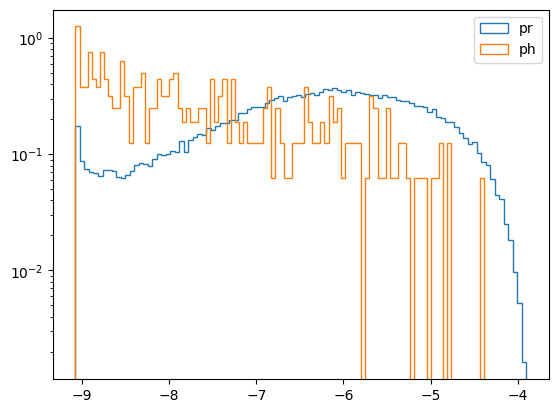

In [35]:

from sklearn.preprocessing import RobustScaler

from sklearn.neighbors import KernelDensity
ch_emb = 6
num =200000
num_ph = 10000
N=13
NUM_STEP=3
bandwidth = 0.3
print(f'part of data {num_ph/num}')
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
index = np.random.choice(len(embading_pr), num, replace=False)
index_ph = np.random.choice(len(embading_photon), num_ph, replace=False)
# with recos

# without recos
feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1)], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1)], axis=1)

feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

label = np.concatenate([np.zeros(num), np.ones(num_ph)])

recos_pr_choise = recos_pr[index]
recos_photon_choise = recos_photon[index_ph]
recos_all_choise = np.concatenate([recos_pr_choise, recos_photon_choise], axis=0)

# shufle
shufle_index = np.random.permutation(len(feaches))
feaches = feaches[shufle_index]
label = label[shufle_index]
recos_all_choise = recos_all_choise[shufle_index]
num_det_feaches = feaches[:,ch_emb]


index_det = (N<=num_det_feaches)*(num_det_feaches<N+NUM_STEP)
X = feaches[index_det][:,:ch_emb].copy()
recos_all_choise = recos_all_choise[index_det]
X = np.concatenate([X[:,:ch_emb], X[:,ch_emb+1:]], axis=1)
print(X.shape)
# Лучше RobustScaler, чем StandardScaler, для задач с выбросами
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)
label_X = label[index_det]
print('pr',(label_X == 0).sum(), 'ph', (label_X == 1).sum())

num=100
index = np.random.randint(0, len(X_scaled), num)
kde = KernelDensity(bandwidth=bandwidth).fit(X_scaled)


scores = kde.score_samples(X_scaled[index])
label_scores = label_X[index]

scores_pr = kde.score_samples(X_scaled[label_X == 0])
scores_ph = kde.score_samples(X_scaled[label_X == 1])
print("CHECK", X_scaled.shape, label_X.shape, recos_all_choise.shape)
recos_pr_choise = recos_all_choise[label_X == 0]
recos_photon_choise = recos_all_choise[label_X == 1]
print(scores_pr.mean(), scores_ph.mean())
print(scores_pr.std(), scores_ph.std())
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.legend()

(47977, 15) (339, 15) (47977,) (339,)





In [37]:
# plot score anomaly by recos
print(recos_pr_choise.shape, recos_photon_choise.shape, scores_pr.shape, scores_ph.shape)
num_recos = recos_pr_choise.shape[1]
fig, ax = plt.subplots(num_recos,1, figsize=(10, 10*num_recos))
for i in range(num_recos):
    ax[i].plot(recos_pr_choise[:,i], scores_pr, '.', label='pr')
    ax[i].plot(recos_photon_choise[:,i], scores_ph, '.', label='ph')
    ax[i].legend()
    ax[i].set_title(f'recos: {name_recos[i]}')
    ax[i].set_xlabel('recos')
    ax[i].set_ylabel('Anomaly score')

In [89]:
def show_del_by_score(pr, ph, use_ph=True, n_ph=1, density_ph = None, density_pr = None, th = 0.1, label_th = 'th'):
    # pr_index= np.random.randint(0, pr.shape[0], size=5000)
    # ph_index= np.random.randint(0, ph.shape[0], size=5000)
    # pr = pr[pr_index]
    # ph = ph[ph_index]
    fig = plt.subplot()
    plt.hist(density_pr, bins=100, label='pr', histtype='step', density=True, log=True)
    plt.hist(density_ph, bins=100, label='ph', histtype='step', density=True, log=True)
    plt.axvline(th, color='k', linestyle='--', label=label_th)
    plt.legend()
    plt.show()
    fig, ax = plt.subplots(2,3, figsize=(12, 12))
    ax_1, ax_2, ax_3 = ax[0]
    reducer = umap.UMAP(n_components=2)
    if use_ph:
        manifold = reducer.fit(np.concatenate([pr, ph[::n_ph]], axis=0))
    else:
        manifold = reducer.fit(pr)
    X_pr = manifold.transform(pr)
    X_ph = manifold.transform(ph)

    X_all = np.vstack([X_pr, X_ph[::n_ph]])

    kde = gaussian_kde(X_all.T, )
    x_min, x_max = X_all[:, 0].min() - 1, X_all[:, 0].max() + 1
    y_min, y_max = X_all[:, 1].min() - 1, X_all[:, 1].max() + 1
    grid_x, grid_y = np.mgrid[x_min:x_max:100j, y_min:y_max:100j]
    density = kde(np.vstack([grid_x.ravel(), grid_y.ravel()]))
    density = density.reshape(grid_x.shape)
    # Используй colormap с белым/очень светлым фоном или полупрозрачный фон, чтобы на нем были хорошо видны и синие и красные точки.
    # Например, вместо яркой bwr, лучше использовать "Greys" с alpha < 1 для фона.
    cmap = plt.colormaps['Greys']
    # (1,0) - плотность для всех точек
    im = ax[0, 2].pcolormesh(grid_x, grid_y, density, cmap=cmap)
    ax[0, 2].set_title('Density')
    fig.colorbar(im, ax=ax[0, 2], label='Density')

    im = ax[1, 2].pcolormesh(grid_x, grid_y, density, cmap=cmap)
    ax[1, 2].set_title('Density')
    ax[0, 0].set_title('Proton all')
    ax[1, 0].set_title('Proton anomaly')
    ax[0, 1].set_title('Photon all')
    ax[1, 1].set_title('Photon anomaly')
    fig.colorbar(im, ax=ax[1, 2], label='Density')

    ax_1, ax_2, ax_3 = ax[0]
    ax_1.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, color='blue', alpha=0.3, label='pr')
    ax_2.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, color='red', alpha=0.3, label='ph')
    ax_3.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, color='blue', alpha=0.3, label='pr')
    ax_3.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, color='red', alpha=0.3, label='ph')
    ax_1.legend()
    ax_2.legend()
    ax_3.legend()

    pr_index = density_pr<th
    ph_index = density_ph<th
    # print(len(density_pr), len(density_ph))
    # print(pr_index.sum(), ph_index.sum())
    # print(len(X_pr[pr_index, 0]), len(X_ph[ph_index, 0]))
    ax_1, ax_2, ax_3 = ax[1]
    ax_1.scatter(X_pr[pr_index, 0], X_pr[pr_index, 1], s=0.5,c='blue', alpha=0.3, label='pr')
    ax_2.scatter(X_ph[ph_index, 0], X_ph[ph_index, 1], s=0.5,c='red',  alpha=0.3, label='ph')
    ax_3.scatter(X_pr[pr_index, 0], X_pr[pr_index, 1], s=0.5,c='blue', alpha=0.3, label='pr')
    ax_3.scatter(X_ph[ph_index, 0], X_ph[ph_index, 1], s=0.5,c='red',  alpha=0.3, label='ph')
    
    # ax[1,1].hist(density_ph, bins=100, label='ph', histtype='step', density=True, log=True)
    # ax[1,1].hist(density_pr, bins=100, label='pr', histtype='step', density=True, log=True)
    # ax[1,1].legend()
    # ax[1,1].set_title('Density (ph and pr)')
    # ax[1,1].grid()
    print('ANOMALY RESULT')
    print(f'pr all : {len(density_pr)}, pr anlomal: {pr_index.sum()}, pr part: {pr_index.sum()/len(density_pr)}')
    print(f'ph all : {len(density_ph)}, ph anlomal: {ph_index.sum()}, ph part: {ph_index.sum()/len(density_ph)}')
    plt.tight_layout()
    plt.show()
    return pr_index, ph_index

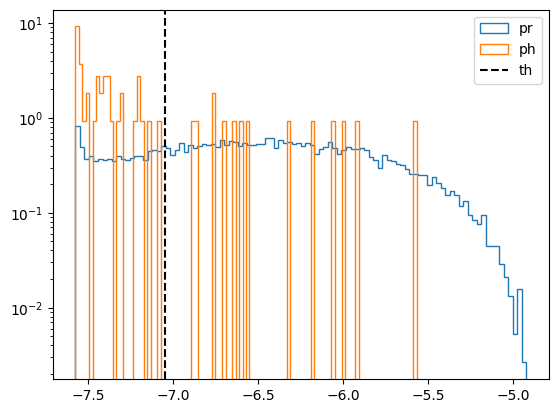

ANOMALY RESULT
pr all : 14295, pr anlomal: 3144, pr part: 0.2199370409233998
ph all : 54, ph anlomal: 40, ph part: 0.7407407407407407


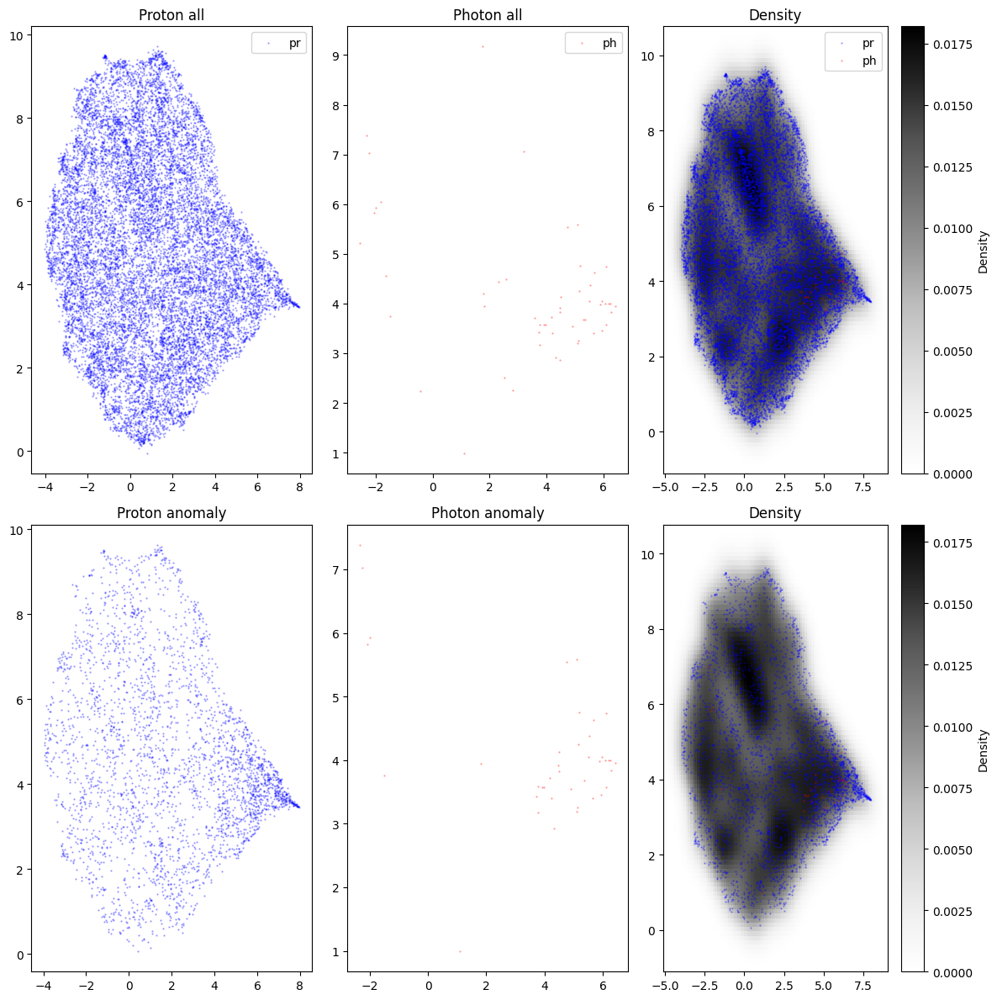

(array([ True, False, False, ..., False, False, False]),
 array([ True,  True, False,  True,  True, False,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True, False, False,
        False,  True, False, False,  True,  True,  True,  True,  True,
         True,  True,  True,  True, False,  True, False,  True,  True,
        False,  True, False,  True, False,  True,  True,  True, False,
         True,  True,  True,  True,  True,  True, False,  True,  True]))

In [90]:
show_del_by_score(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=scores_ph, density_pr=scores_pr, th=-7.05)

(14295, 15) (54, 15) (14295,) (54,)





In [91]:
# plot score anomaly by recos
print(recos_pr_choise.shape, recos_photon_choise.shape, scores_pr.shape, scores_ph.shape)
num_recos = recos_pr_choise.shape[1]
fig, ax = plt.subplots(num_recos,1, figsize=(10, 10*num_recos))
for i in range(num_recos):
    ax[i].plot(recos_pr_choise[:,i], scores_pr, '.', label='pr')
    ax[i].plot(recos_photon_choise[:,i], scores_ph, '.', label='ph')
    ax[i].legend()
    ax[i].set_title(f'recos: {name_recos[i]}')
    ax[i].set_xlabel('recos')

In [42]:
import numpy as np
from sklearn.metrics import average_precision_score

def AUCPR(score_samples_pr, score_samples_photon):
    """
    Вычисляет Average Precision (AUC-PR) для задачи обнаружения аномалий.
    
    Параметры:
    -----------
    score_samples_pr : array-like
        Значения скора аномальности для нормальных объектов (протоны).
        Ожидается, что для нормальных объектов скор будет ниже.
    score_samples_photon : array-like
        Значения скора аномальности для аномальных объектов (фотоны).
        Ожидается, что для аномалий скор будет выше.
    
    Возвращает:
    -----------
    float
        Значение Average Precision (AUC-PR) в диапазоне [0, 1].
        Чем ближе к 1, тем лучше модель разделяет классы.
    
    Примечание:
    -----------
    - Функция предполагает, что более высокий скор означает большую вероятность
      принадлежности к классу аномалий (положительному классу).
    - Если в вашей модели наоборот (низкий скор = аномалия), используйте
      `-score` при передаче или умножьте скоры на -1.
    - Для сильно несбалансированных датасетов AUC-PR является предпочтительной
      метрикой по сравнению с AUC-ROC.
    """
    # Формируем истинные метки: 0 – норма, 1 – аномалия
    y_true = np.concatenate([np.zeros_like(score_samples_pr),
                             np.ones_like(score_samples_photon)])
    # Формируем массив скоров (в том же порядке)
    y_score = np.concatenate([score_samples_pr, score_samples_photon])
    
    # Вычисляем Average Precision
    return average_precision_score(y_true, y_score)
def thershold_for_quantile(score_samples, quantiles = [0.05, 0.1, 0.2, 0.25, 0.3]):
    th_list = []
    for q in quantiles:
        th = np.percentile(score_samples, q)
        print(f'{q} quantile: {th}')
        th_list.append(th)
    return th_list
thershold_for_quantile(scores_pr)
thershold_for_quantile(scores_ph)



0.05 quantile: -7.573054599564429
0.1 quantile: -7.5730545995585326
0.2 quantile: -7.573054585944284
0.25 quantile: -7.5730545389542145
0.3 quantile: -7.573054431712744
0.05 quantile: -7.573054598696321
0.1 quantile: -7.573054598167929
0.2 quantile: -7.5730545971111445
0.25 quantile: -7.573054596582753
0.3 quantile: -7.5730545960543605


[-7.573054598696321,
 -7.573054598167929,
 -7.5730545971111445,
 -7.573054596582753,
 -7.5730545960543605]

pr (210315, 6) ph (210851, 6)
(15119, 7)
pr 15044 ph 75
-6.531616755065907 -7.416137082680052
0.6668161952160573 0.41319011717331766
0.05 quantile: -7.6284676121309225
0.1 quantile: -7.628467612095814
0.2 quantile: -7.62846758871281
0.25 quantile: -7.628467461882328
0.3 quantile: -7.6284672174929575


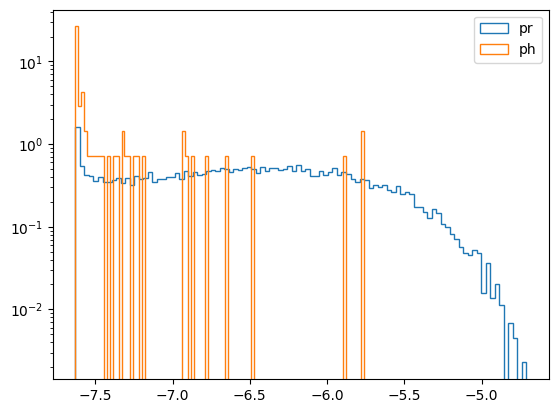

In [43]:
ch_emb = 6
part_ph_on_pr = 0.005
N = 15
bandwidth = 0.3
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
index = np.random.randint(0, len(embading_pr), num)
index_ph = np.random.randint(0, len(embading_photon), num_ph)
# with recos

index_pr_N_det = np.where(num_det_pr == N)[0]
index_ph_N_det = np.where(num_det_photon == N)[0]

# without recos
feaches_pr = np.concatenate([embading_pr[index_pr_N_det], num_det_pr[index_pr_N_det].reshape(-1,1), recon_loss_pr[index_pr_N_det].reshape(-1,1)], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph_N_det], num_det_photon[index_ph_N_det].reshape(-1,1), recon_loss_photon[index_ph_N_det].reshape(-1,1)], axis=1)


index_ph = np.random.randint(0, len(feaches_photon), int(len(feaches_pr)*part_ph_on_pr))
feaches_photon = feaches_photon[index_ph]
feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

label = np.concatenate([np.zeros(len(feaches_pr)), np.ones(len(feaches_photon))])

# shufle
shufle_index = np.random.permutation(len(feaches))
feaches = feaches[shufle_index]
label = label[shufle_index]

num_det_feaches = feaches[:,ch_emb]



X = feaches.copy()
X = np.concatenate([X[:,:ch_emb], X[:,ch_emb+1:]], axis=1)
print(X.shape)
# Лучше RobustScaler, чем StandardScaler, для задач с выбросами
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)
label_X = label
print('pr',(label_X == 0).sum(), 'ph', (label_X == 1).sum())


num=2000
index = np.random.randint(0, len(X_scaled), num)
kde = KernelDensity(bandwidth=bandwidth).fit(X_scaled)


scores = kde.score_samples(X_scaled[index])
label_scores = label_X[index]

scores_pr = kde.score_samples(X_scaled[label_X == 0])
scores_ph = kde.score_samples(X_scaled[label_X == 1])
print(scores_pr.mean(), scores_ph.mean())
print(scores_pr.std(), scores_ph.std())
thersholds = thershold_for_quantile(scores_pr)
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.legend()

0.05 percentile: -7.597010298151808
0.1 percentile: -7.499605244558664
0.2 percentile: -7.228470103919086


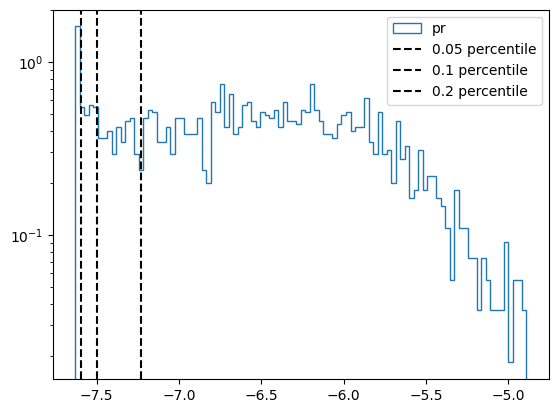

-6.555883272830546 0.6635378181190772 (2000,)


In [47]:
def show_precentile(scores, percentiles = [0.05, 0.1, 0.2]):   
    plt.hist(scores, bins=100, label='pr', histtype='step', density=True, log=True)
    for p in percentiles:
        th = np.percentile(scores, p*100)
        print(f'{p} percentile: {th}')
        plt.axvline(th, color='k', linestyle='--', label=f'{p} percentile')
    plt.legend()
    plt.show()
    return th   
th = show_precentile(scores)
print(scores.mean(), scores.std(), scores.shape)

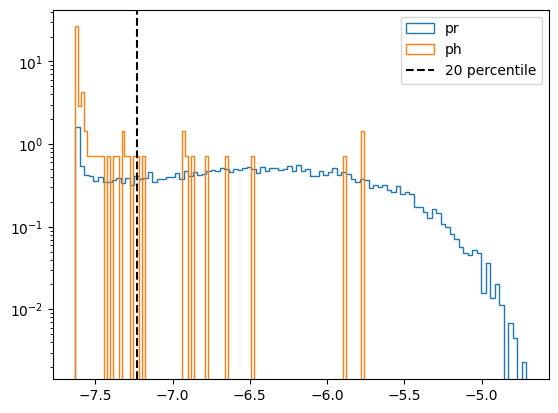

ANOMALY RESULT
pr all : 15044, pr anlomal: 2874, pr part: 0.19103961712310555
ph all : 75, ph anlomal: 64, ph part: 0.8533333333333334


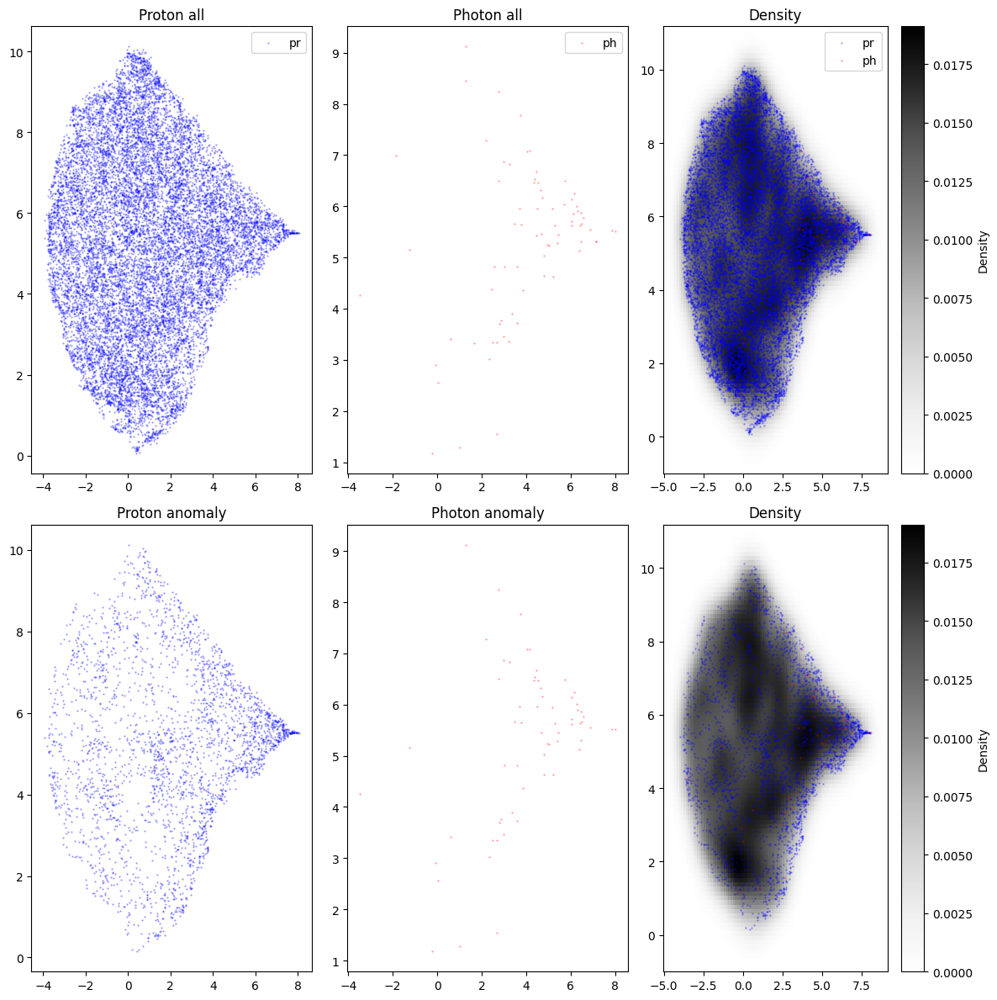

(array([False,  True,  True, ..., False, False, False]),
 array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        False,  True,  True,  True,  True,  True,  True,  True, False,
         True,  True, False,  True, False, False,  True,  True, False,
         True,  True,  True,  True,  True,  True,  True,  True, False,
         True,  True,  True,  True,  True,  True,  True,  True,  True,
         True, False,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True, False,  True,  True,  True,
        False,  True,  True,  True,  True,  True,  True,  True,  True,
        False,  True,  True]))

In [52]:
show_del_by_score(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=scores_ph, density_pr=scores_pr, th=th, label_th = '20 percentile')

In [56]:
def get_values_by_part(part_ph_on_pr_list = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2],
                        num_by_one_part = 10,
                        precentile = 0.2):
    result_parts = {}
    for part_ph_on_pr in tqdm(part_ph_on_pr_list, desc='ALL PARTS'):
        num_pr = 50000
        num_ph = int(num_pr*part_ph_on_pr)
        result_parts[part_ph_on_pr] = []
        for i in tqdm(range(num_by_one_part), desc=f'part {part_ph_on_pr}'):
            ch_emb = 6
            N = 15
            bandwidth = 0.3
            index = np.random.randint(0, len(embading_pr), num_pr)
            index_ph = np.random.randint(0, len(embading_photon), num_ph)
            # with recos

            index_pr_N_det = np.where(num_det_pr == N)[0]
            index_ph_N_det = np.where(num_det_photon == N)[0]

            # without recos
            feaches_pr = np.concatenate([embading_pr[index_pr_N_det], num_det_pr[index_pr_N_det].reshape(-1,1), recon_loss_pr[index_pr_N_det].reshape(-1,1)], axis=1)

            feaches_photon = np.concatenate([embading_photon[index_ph_N_det], num_det_photon[index_ph_N_det].reshape(-1,1), recon_loss_photon[index_ph_N_det].reshape(-1,1)], axis=1)


            index_ph = np.random.randint(0, len(feaches_photon), int(len(feaches_pr)*part_ph_on_pr))
            feaches_photon = feaches_photon[index_ph]
            feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

            label = np.concatenate([np.zeros(len(feaches_pr)), np.ones(len(feaches_photon))])

            # shufle
            shufle_index = np.random.permutation(len(feaches))
            feaches = feaches[shufle_index]
            label = label[shufle_index]

            num_det_feaches = feaches[:,ch_emb]



            X = feaches.copy()
            X = np.concatenate([X[:,:ch_emb], X[:,ch_emb+1:]], axis=1)
            # Лучше RobustScaler, чем StandardScaler, для задач с выбросами
            scaler = RobustScaler()
            X_scaled = scaler.fit_transform(X)
            label_X = label


            num=2000
            index = np.random.randint(0, len(X_scaled), num)
            kde = KernelDensity(bandwidth=bandwidth).fit(X_scaled)


            scores = kde.score_samples(X_scaled[index])
            label_scores = label_X[index]

            scores_pr = kde.score_samples(X_scaled[label_X == 0])
            scores_ph = kde.score_samples(X_scaled[label_X == 1])

            th = np.percentile(scores, precentile*100)
            pr_index = scores_pr<th
            ph_index = scores_ph<th

            res = {}
            res['pr'] = len(pr_index)
            res['ph'] = len(ph_index)
            res['anomalys_pr'] = pr_index.sum()
            res['anomalys_ph'] = ph_index.sum()
            res['part_anomalys_pr'] = pr_index.sum()/len(pr_index)
            res['part_anomalys_ph'] = ph_index.sum()/len(ph_index)
            result_parts[part_ph_on_pr].append(res)
    return result_parts
result_parts = get_values_by_part()


ALL PARTS:   0%|          | 0/6 [00:00<?, ?it/s]

part 0.005:   0%|          | 0/10 [00:00<?, ?it/s]

part 0.01:   0%|          | 0/10 [00:00<?, ?it/s]

part 0.02:   0%|          | 0/10 [00:00<?, ?it/s]

part 0.05:   0%|          | 0/10 [00:00<?, ?it/s]

part 0.1:   0%|          | 0/10 [00:00<?, ?it/s]

part 0.2:   0%|          | 0/10 [00:00<?, ?it/s]

{0.005: [{'pr': 15044, 'ph': 75, 'anomalys_pr': 3046, 'anomalys_ph': 61, 'part_anomalys_pr': 0.20247274660994416, 'part_anomalys_ph': 0.8133333333333334}, {'pr': 15044, 'ph': 75, 'anomalys_pr': 3040, 'anomalys_ph': 58, 'part_anomalys_pr': 0.20207391651156606, 'part_anomalys_ph': 0.7733333333333333}, {'pr': 15044, 'ph': 75, 'anomalys_pr': 2775, 'anomalys_ph': 59, 'part_anomalys_pr': 0.18445892049986706, 'part_anomalys_ph': 0.7866666666666666}, {'pr': 15044, 'ph': 75, 'anomalys_pr': 3020, 'anomalys_ph': 64, 'part_anomalys_pr': 0.20074448285030577, 'part_anomalys_ph': 0.8533333333333334}, {'pr': 15044, 'ph': 75, 'anomalys_pr': 2966, 'anomalys_ph': 61, 'part_anomalys_pr': 0.19715501196490295, 'part_anomalys_ph': 0.8133333333333334}, {'pr': 15044, 'ph': 75, 'anomalys_pr': 3066, 'anomalys_ph': 56, 'part_anomalys_pr': 0.20380218027120447, 'part_anomalys_ph': 0.7466666666666667}, {'pr': 15044, 'ph': 75, 'anomalys_pr': 2863, 'anomalys_ph': 63, 'part_anomalys_pr': 0.19030842860941238, 'part_anom

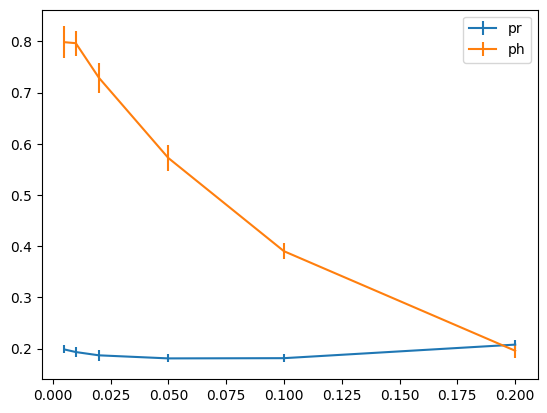

In [66]:
print(result_parts)
mean_part_pr = []
mean_part_ph = []
std_part_pr = []
std_part_ph = []
th_list = []
for th, part in result_parts.items():
    part_pr = []
    part_ph = []
    for d in part:
        part_pr.append(d['part_anomalys_pr'])
        part_ph.append(d['part_anomalys_ph'])
    mean_part_pr.append(np.mean(part_pr))
    mean_part_ph.append(np.mean(part_ph))
    std_part_pr.append(np.std(part_pr))
    std_part_ph.append(np.std(part_ph))
    th_list.append(th)
plt.errorbar(th_list, mean_part_pr, yerr=std_part_pr, label='pr')
plt.errorbar(th_list, mean_part_ph, yerr=std_part_ph, label='ph')
# for th in th_list:
#     plt.text(th, 0.5, f'{mean_part_pr[th_list.index(th)]:.3f}')
plt.legend()
plt.show()

In [ ]:
def get_values_by_NUM(NUM_DET = np.arange(5, 30),
                        precentile = 0.2,
                        part_ph_on_pr = 0.01):
    result_parts = {}
    for N in tqdm(NUM_DET, desc='ALL N'):
        num_pr = 50000
        num_ph = int(num_pr*part_ph_on_pr)
        result_parts[part_ph_on_pr] = []
        ch_emb = 6
        bandwidth = 0.3
        index = np.random.randint(0, len(embading_pr), num_pr)
        index_ph = np.random.randint(0, len(embading_photon), num_ph)
        # with recos

        index_pr_N_det = np.where(num_det_pr == N)[0]
        index_ph_N_det = np.where(num_det_photon == N)[0]

        # without recos
        feaches_pr = np.concatenate([embading_pr[index_pr_N_det], num_det_pr[index_pr_N_det].reshape(-1,1), recon_loss_pr[index_pr_N_det].reshape(-1,1)], axis=1)

        feaches_photon = np.concatenate([embading_photon[index_ph_N_det], num_det_photon[index_ph_N_det].reshape(-1,1), recon_loss_photon[index_ph_N_det].reshape(-1,1)], axis=1)


        index_ph = np.random.randint(0, len(feaches_photon), int(len(feaches_pr)*part_ph_on_pr))
        feaches_photon = feaches_photon[index_ph]
        feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

        label = np.concatenate([np.zeros(len(feaches_pr)), np.ones(len(feaches_photon))])

        # shufle
        shufle_index = np.random.permutation(len(feaches))
        feaches = feaches[shufle_index]
        label = label[shufle_index]

        num_det_feaches = feaches[:,ch_emb]



        X = feaches.copy()
        X = np.concatenate([X[:,:ch_emb], X[:,ch_emb+1:]], axis=1)
        # Лучше RobustScaler, чем StandardScaler, для задач с выбросами
        scaler = RobustScaler()
        X_scaled = scaler.fit_transform(X)
        label_X = label


        num=2000
        index = np.random.randint(0, len(X_scaled), num)
        kde = KernelDensity(bandwidth=bandwidth).fit(X_scaled)


        scores = kde.score_samples(X_scaled[index])
        label_scores = label_X[index]

        scores_pr = kde.score_samples(X_scaled[label_X == 0])
        scores_ph = kde.score_samples(X_scaled[label_X == 1])

        th = np.percentile(scores, precentile*100)
        pr_index = scores_pr<th
        ph_index = scores_ph<th

        res = {}
        res['pr'] = len(pr_index)
        res['ph'] = len(ph_index)
        res['anomalys_pr'] = pr_index.sum()
        res['anomalys_ph'] = ph_index.sum()
        res['part_anomalys_pr'] = pr_index.sum()/len(pr_index)
        res['part_anomalys_ph'] = ph_index.sum()/len(ph_index)
        result_parts[N] = res
    return result_parts
result_parts_num = get_values_by_NUM()
print(result_parts_num)

ALL N:   0%|          | 0/25 [00:00<?, ?it/s]

KeyError: 5

In [46]:
# В изначально ненормированных данных val*10^18

# После нормировки 
# 0- это 0
# 1.0 энергия 10^18
# 10.0 энергия 10^19

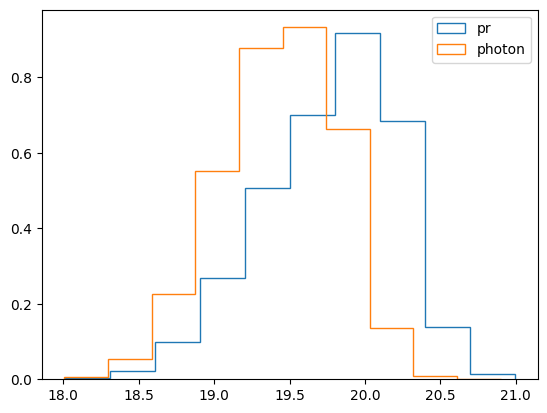

In [ ]:
Energy_pr = np.log10(recos_norming_pr[:,3])+18
Energy_photon = np.log10(recos_norming_photon[:,3])+18
plt.hist(Energy_pr,histtype='step',density=True, label='pr')
plt.hist(Energy_photon,histtype='step',density=True, label='photon')
plt.legend()


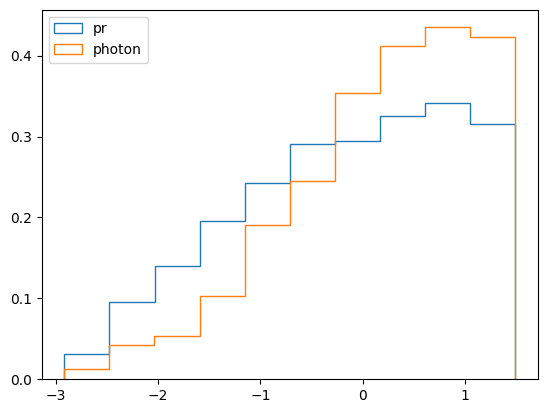

In [ ]:
plt.hist(recos_pr[:,0],histtype='step',density=True, label='pr')
plt.hist(recos_photon[:,0],histtype='step',density=True, label='photon')
plt.legend()

In [ ]:
def get_metrics(score_samples, score_samples_photon, th):
    FP_index = np.where(score_samples < th)[0]
    TP_index = np.where(score_samples_photon < th)[0]
    FN_index = np.where(score_samples_photon > th)[0]
    TN_index = np.where(score_samples > th)[0]
    part_anomalys_pr = len(FP_index)/len(score_samples)
    part_anomalys_ph = len(TP_index)/len(score_samples_photon)
    recall = len(TP_index) / (len(TP_index) + len(FN_index)+1e-10)
    precision = len(TP_index) / (len(TP_index) + len(FP_index)+1e-10)
    f1 = 2 * precision * recall / (precision + recall+1e-10)
    return recall, precision, f1, part_anomalys_pr, part_anomalys_ph

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.neighbors import KernelDensity
def full_test_prob(feaches_pr, feaches_photon,feaches_pr_test = None,n_components=1, range_hist=(-20, 0)):
    fig, axs = plt.subplots(3, 1, figsize=(7, 15))
    # clf = mixture.GaussianMixture(n_components=n_components, covariance_type="full")
    clf = KernelDensity(kernel='gaussian', bandwidth=0.1)
    clf.fit(feaches_pr)
    if feaches_pr_test is None:
        score_samples = clf.score_samples(feaches_pr)
        score_samples_photon = clf.score_samples(feaches_photon)
    else:
        score_samples = clf.score_samples(feaches_pr_test)
        score_samples_photon = clf.score_samples(feaches_photon)
    print(score_samples)
    print(score_samples_photon)
    axs[0].hist(score_samples, bins=100, label='pr', histtype='step', density=True, range=range_hist)
    axs[0].hist(score_samples_photon, bins=100, label='ph', histtype='step', density=True, range=range_hist)
    axs[0].legend()
    axs[0].set_title('hist')
    axs[0].grid()

    recall_list = []    
    precision_list = []
    f1_list = []
    part_anomalys_pr_list = []
    part_anomalys_ph_list = []
    min_score = min(score_samples.min(), score_samples_photon.min())
    max_score = max(score_samples.max(), score_samples_photon.max())
    for th in np.linspace(min_score, max_score, 100):
        recall, precision, f1, part_anomalys_pr, part_anomalys_ph = get_metrics(score_samples, score_samples_photon, th)
        recall_list.append(recall)
        precision_list.append(precision)
        f1_list.append(f1)
        part_anomalys_pr_list.append(part_anomalys_pr)
        part_anomalys_ph_list.append(part_anomalys_ph)
    axs[1].plot(np.linspace(-20, 2, 100), recall_list, label='recall')
    axs[1].plot(np.linspace(-20, 2, 100), precision_list, label='precision')
    axs[1].plot(np.linspace(-20, 2, 100), f1_list, label='f1')
    axs[1].plot(np.linspace(-20, 2, 100), part_anomalys_pr_list, label='part_anomalys_pr')
    axs[1].plot(np.linspace(-20, 2, 100), part_anomalys_ph_list, label='part_anomalys_ph')
    axs[1].legend()
    axs[1].set_title('metrics')
    axs[1].grid()

    #roc curve
    label_pr = np.zeros_like(score_samples)
    label_ph = np.ones_like(score_samples_photon)
    label = np.concatenate((label_pr, label_ph))
    loss = np.concatenate((-score_samples, -score_samples_photon))
    fpr, tpr, thresholds = roc_curve(label, loss)
    auc_ = auc(fpr, tpr)
    axs[2].plot(fpr, tpr)
    axs[2].text(0.5, 0.5, f'auc: {auc_:.2f}', fontsize=12, ha='center', va='center')
    axs[2].set_title(f'roc curve')
    axs[2].grid()
    print(thresholds.min(), thresholds.max())
    plt.show()

    
    

In [ ]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import RobustScaler
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.ensemble import IsolationForest

num =47000
num_ph = 400
print(f'part of data {num_ph/num}')
test_num = 10000
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
index = np.random.randint(0, len(embading_pr), num)
index_ph = np.random.randint(0, len(embading_photon), num_ph)
feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1), recos_pr[index]], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1), recos_photon[index_ph]], axis=1)

feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)
# label_pr = np.zeros(num)
# label_ph = np.ones(num_ph)
# label = np.concatenate((label_pr, label_ph))
# feaches_pr_test = np.concatenate([embading_pr[-test_num:], num_det_pr[-test_num:].reshape(-1,1), recon_loss_pr[-test_num:].reshape(-1,1)], axis=1)

# feaches_photon_test = np.concatenate([embading_photon[-test_num:], num_det_photon[-test_num:].reshape(-1,1), recon_loss_photon[-test_num:].reshape(-1,1)], axis=1)
# feaches: твой массив shape [N, D]
X = feaches.copy()
print(X.shape)
# Лучше RobustScaler, чем StandardScaler, для задач с выбросами
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

part of data 0.00851063829787234
pr (210315, 6) ph (210851, 6)
(47400, 23)


In [ ]:
# embading, num_det, recon_loss, recos
print(feaches.shape)

(47400, 23)


In [ ]:
def show_2d(pr, ph, use_ph=True):
    # pr_index= np.random.randint(0, pr.shape[0], size=5000)
    # ph_index= np.random.randint(0, ph.shape[0], size=5000)
    # pr = pr[pr_index]
    # ph = ph[ph_index]
    reducer = umap.UMAP(n_components=2)
    if use_ph:
        manifold = reducer.fit(np.concatenate([pr, ph], axis=0))
    else:
        manifold = reducer.fit(pr)
    X_pr = manifold.transform(pr)
    X_ph = manifold.transform(ph)


    fig, ax = plt.subplots(2,3, figsize=(12, 12))
    ax_1, ax_2, ax_3 = ax[0]
    ax_1.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_2.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_3.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_1.legend()
    ax_2.legend()
    ax_3.legend()

    # tsne = sklearn.manifold.TSNE(n_components=2)
    # if use_ph:
    #     X_tsne = tsne.fit_transform(np.concatenate([pr, ph], axis=0))
    #     X_tsne_pr = X_tsne[:pr.shape[0]]
    #     X_tsne_ph = X_tsne[pr.shape[0]:]
    # else:
    #     X_tsne = tsne.fit_transform(pr)
    #     X_tsne_pr = X_tsne

    # ax_1, ax_2, ax_3 = ax[1]
    # ax_1.scatter(X_tsne_pr[:, 0], X_tsne_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    # ax_2.scatter(X_tsne_ph[:, 0], X_tsne_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    # ax_3.scatter(X_tsne_pr[:, 0], X_tsne_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    # ax_3.scatter(X_tsne_ph[:, 0], X_tsne_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    # ax_1.legend()
    # ax_2.legend()
    # ax_3.legend()
    plt.show()

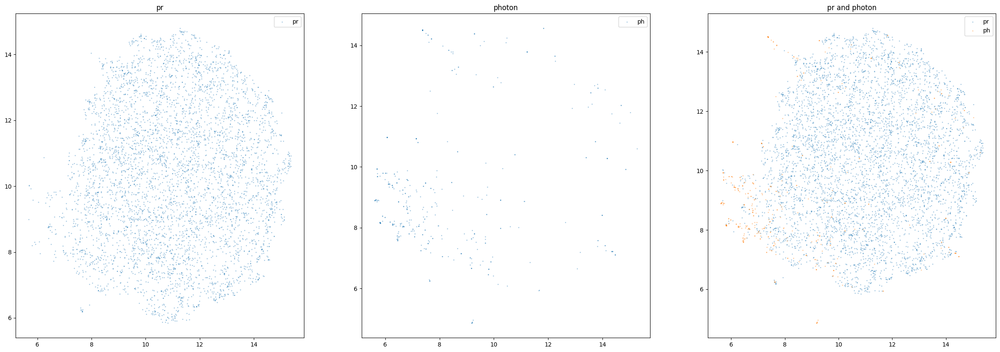

In [ ]:
pr = feaches_pr[np.random.randint(0, feaches_pr.shape[0], size=5000)][:,:6]
ph = feaches_photon[np.random.randint(0, feaches_photon.shape[0], size=400)][:,:6]
use_ph = True
fig, ax = plt.subplots(1,3, figsize=(30, 10))

reducer = umap.UMAP(n_components=2)
if use_ph:
    manifold = reducer.fit(np.concatenate([pr, ph], axis=0))
else:
    manifold = reducer.fit(pr)
X_pr = manifold.transform(pr)
X_ph = manifold.transform(ph)

ax_1, ax_2, ax_3 = ax
ax_1.scatter(X_pr[:, 0], X_pr[:, 1], s=1, alpha=0.3, label='pr')
ax_2.scatter(X_ph[:, 0], X_ph[:, 1], s=1, alpha=0.3, label='ph')
ax_3.scatter(X_pr[:, 0], X_pr[:, 1], s=1, alpha=0.3, label='pr')
ax_3.scatter(X_ph[:, 0], X_ph[:, 1], s=1, alpha=0.3, label='ph')
ax_1.set_title('pr')
ax_2.set_title('photon')
ax_3.set_title('pr and photon')
ax_1.legend()
ax_2.legend()
ax_3.legend()


In [ ]:
from scipy.stats import gaussian_kde
def show_2d_density(pr, ph, use_ph=True, n_ph=1, density_ph = None, density_pr = None):
    # pr_index= np.random.randint(0, pr.shape[0], size=5000)
    # ph_index= np.random.randint(0, ph.shape[0], size=5000)
    # pr = pr[pr_index]
    # ph = ph[ph_index]
    reducer = umap.UMAP(n_components=2)
    if use_ph:
        manifold = reducer.fit(np.concatenate([pr, ph[::n_ph]], axis=0))
    else:
        manifold = reducer.fit(pr)
    X_pr = manifold.transform(pr)
    X_ph = manifold.transform(ph)

    fig, ax = plt.subplots(2,3, figsize=(12, 12))
    ax_1, ax_2, ax_3 = ax[0]
    ax_1.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_2.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_3.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_1.legend()
    ax_2.legend()
    ax_3.legend()

    X_all = np.vstack([X_pr, X_ph[::n_ph]])
    kde = gaussian_kde(X_all.T, )
    density = kde(X_all.T)  # shape: (N,)


    x_min, x_max = X_all[:, 0].min() - 1, X_all[:, 0].max() + 1
    y_min, y_max = X_all[:, 1].min() - 1, X_all[:, 1].max() + 1
    grid_x, grid_y = np.mgrid[x_min:x_max:100j, y_min:y_max:100j]
    density = kde(np.vstack([grid_x.ravel(), grid_y.ravel()]))
    density = density.reshape(grid_x.shape)

    ax_1, ax_2, ax_3 = ax[1]
    # Отображение плотности
    cmap = plt.colormaps['PiYG']
    # (1,0) - плотность для всех точек
    im = ax[1, 0].pcolormesh(grid_x, grid_y, density, cmap=cmap)
    ax[1, 0].set_title('Density (all)')
    fig.colorbar(im, ax=ax[1, 0], label='Density')
    
    ax[1,0].scatter(X_ph[:, 0], X_ph[:, 1],s=1, label='ph')
    # (1,1) и (1,2) можно оставить пустыми или повторить для pr и ph отдельно
    if density_ph is None:
        density_ph = kde(X_ph.T)
    if density_pr is None:
        density_pr = kde(X_pr.T)
    
    im = ax[1, 2].scatter(X_ph[:, 0], X_ph[:, 1], s=1, label='ph', c=density_ph, cmap='viridis')
    ax[1, 2].set_title('Density (ph)')
    fig.colorbar(im, ax=ax[1, 2], label='Density')
    
    ax[1,1].hist(density_ph, bins=100, label='ph', histtype='step', density=True, log=True)
    ax[1,1].hist(density_pr, bins=100, label='pr', histtype='step', density=True, log=True)
    ax[1,1].legend()
    ax[1,1].set_title('Density (ph and pr)')
    ax[1,1].grid()

    plt.tight_layout()
    plt.show()

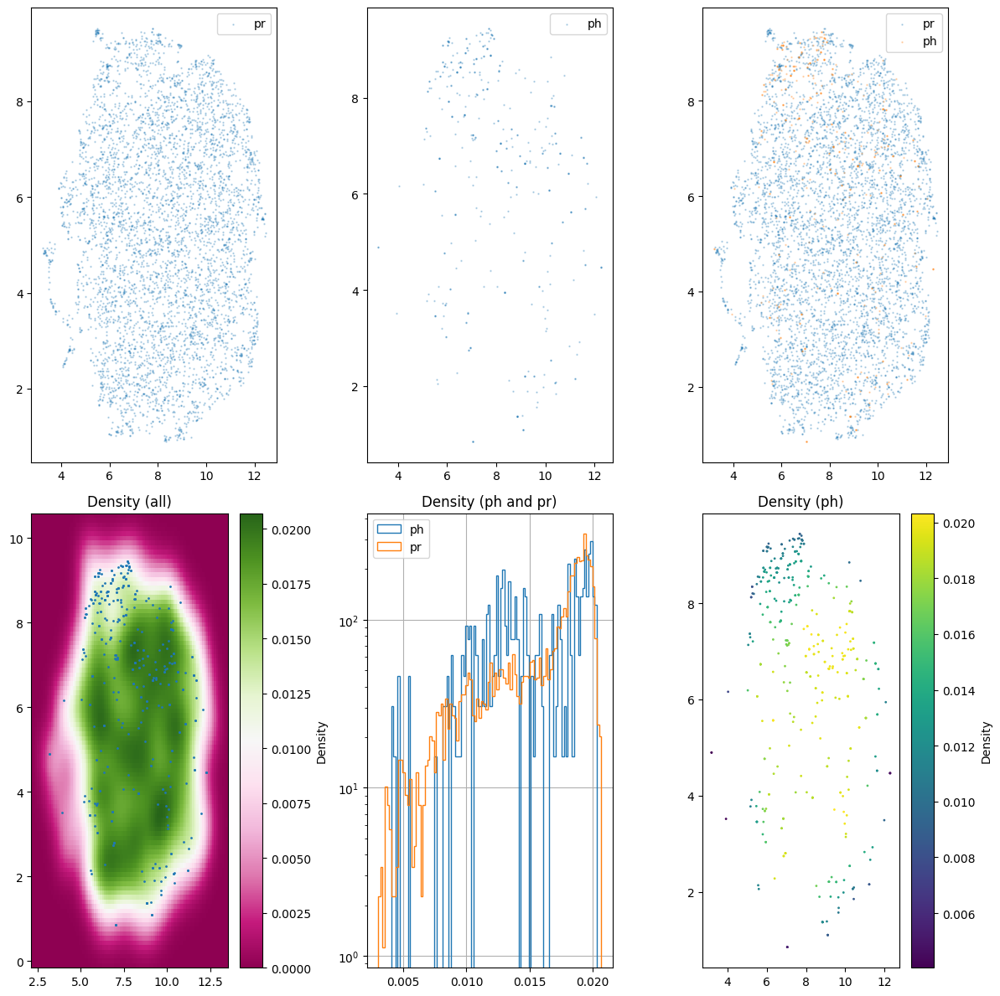

In [ ]:
show_2d_density(pr[:10000],ph[:1000], n_ph=10)

In [ ]:
def get_metrics(score_samples, score_samples_photon, th):
    FP_index = np.where(score_samples > th)[0]
    TP_index = np.where(score_samples_photon > th)[0]
    FN_index = np.where(score_samples_photon > th)[0]
    TN_index = np.where(score_samples < th)[0]
    part_anomalys_pr = len(FP_index)/len(score_samples)
    part_anomalys_ph = len(TP_index)/len(score_samples_photon)
    recall = len(TP_index) / (len(TP_index) + len(FN_index)+1e-10)
    precision = len(TP_index) / (len(TP_index) + len(FP_index)+1e-10)
    f1 = 2 * precision * recall / (precision + recall+1e-10)
    return recall, precision, f1, part_anomalys_pr, part_anomalys_ph
def get_top_anomalies(scores, top_percent=1.0):
    """
    Возвращает индексы top_percent самых аномальных точек.
    Чем больше score, тем более аномальна точка.
    """
    n_top = max(1, int(len(scores) * top_percent / 100.0))
    idx_sorted = np.argsort(scores)[::-1]   # по убыванию anomaly score
    top_idx = idx_sorted[:n_top]
    return top_idx, scores[top_idx]

def make_result_df(scores, name="score"):
    df = pd.DataFrame({
        "index": np.arange(len(scores)),
        name: scores
    })
    df = df.sort_values(name, ascending=False).reset_index(drop=True)
    return df

In [ ]:
def iforest_anomaly_score(X_scaled, n_estimators=300, max_samples="auto", random_state=42):
    """
    Isolation Forest.
    Чем больше score, тем более аномальна точка.
    """
    clf = IsolationForest(
        n_estimators=n_estimators,
        max_samples=max_samples,
        contamination=0.025,
        random_state=random_state,
        n_jobs=-1
    )

    clf.fit(X_scaled)

    # score_samples: больше = более нормальная точка
    # берем минус, чтобы больше = более аномальная
    scores = -clf.score_samples(X_scaled)

    return scores

iforest_scores = iforest_anomaly_score(X_scaled[:,:8], n_estimators=100, random_state=42)
df_iforest = make_result_df(iforest_scores, name="iforest_score")


    index  iforest_score particle
0   32532       0.700686       pr
1    5359       0.684411       pr
2   13980       0.684095       pr
3    5258       0.683557       pr
4   17244       0.683557       pr
5   31760       0.682809       pr
6    3102       0.682809       pr
7   26741       0.682242       pr
8   14195       0.676200       pr
9   25853       0.666233       pr
10  42146       0.662205       pr
11  18283       0.659270       pr
12  36506       0.658127       pr
13  12238       0.656993       pr
14  28177       0.655753       pr
15  22077       0.655413       pr
16  19072       0.654894       pr
17  35830       0.654882       pr
18   8413       0.654435       pr
19  12075       0.653742       pr
       index  iforest_score particle
47380  24761       0.374219       pr
47381  42350       0.374213       pr
47382  18759       0.374096       pr
47383  15206       0.374096       pr
47384  24201       0.374055       pr
47385  39141       0.374055       pr
47386   7676       0.373918

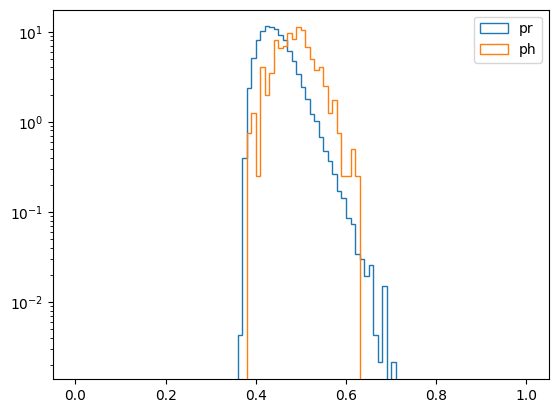

In [ ]:
df_iforest['particle'] = np.where(df_iforest['index'] < num, 'pr', 'ph')
print(df_iforest.head(20))
print(df_iforest.tail(20))
print(len(df_iforest[df_iforest['particle'] == 'pr']))
print(len(df_iforest[df_iforest['particle'] == 'ph']))
print(len(df_iforest))
plt.hist(df_iforest[df_iforest['particle'] == 'pr']['iforest_score'], bins=100, label='pr', log=True, density=True, histtype='step', range=(0, 1))
plt.hist(df_iforest[df_iforest['particle'] == 'ph']['iforest_score'], bins=100, label='ph', log=True, density=True, histtype='step', range=(0, 1))
plt.legend()
plt.show()

(47000,) (400,)


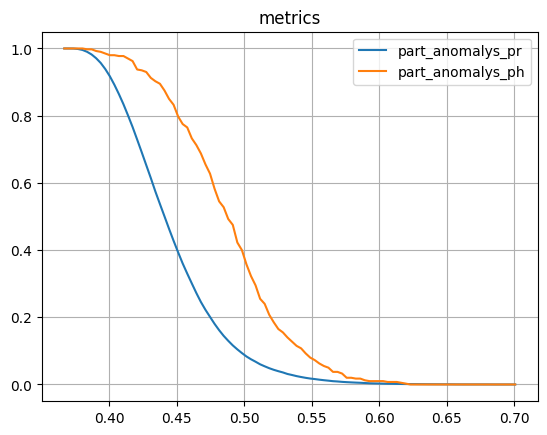

In [ ]:
value = np.array(df_iforest['iforest_score'])
label_df = np.where(df_iforest['particle'] == 'pr', 0, 1)
score_samples = value[label_df == 0]
score_samples_photon = value[label_df == 1]
print(score_samples.shape, score_samples_photon.shape)
recall_list = []    
precision_list = []
f1_list = []
part_anomalys_pr_list = []
part_anomalys_ph_list = []
min_score = min(score_samples.min(), score_samples_photon.min())
max_score = max(score_samples.max(), score_samples_photon.max())
for th in np.linspace(min_score, max_score, 100):
    recall, precision, f1, part_anomalys_pr, part_anomalys_ph = get_metrics(score_samples, score_samples_photon, th)
    recall_list.append(recall)
    precision_list.append(precision)
    f1_list.append(f1)
    part_anomalys_pr_list.append(part_anomalys_pr)
    part_anomalys_ph_list.append(part_anomalys_ph)
# plt.plot(np.linspace(min_score, max_score, 100), recall_list, label='recall')
# plt.plot(np.linspace(min_score, max_score, 100), precision_list, label='precision')
# plt.plot(np.linspace(min_score, max_score, 100), f1_list, label='f1')
plt.plot(np.linspace(min_score, max_score, 100), part_anomalys_pr_list, label='part_anomalys_pr')
plt.plot(np.linspace(min_score, max_score, 100), part_anomalys_ph_list, label='part_anomalys_ph')
plt.legend()
plt.title('metrics')
plt.grid()

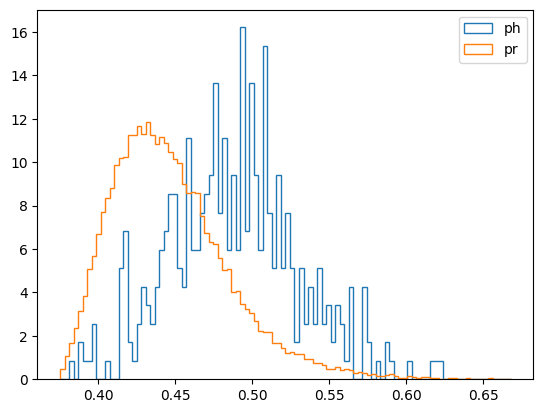

array([0.70068594, 0.68441061, 0.68409451, ..., 0.37068233, 0.36985373,
       0.36678755])

In [ ]:
plt.hist(score_samples_photon, bins=100, label='ph', histtype='step', density=True, range=(0.375, 0.668))
plt.hist(score_samples, bins=100, label='pr', histtype='step', density=True, range=(0.375, 0.668))
plt.legend()
plt.show()
value


(array([ 0.        ,  0.        ,  0.85324232,  0.        ,  1.70648464,
         0.85324232,  0.85324232,  2.55972696,  0.        ,  0.        ,
         0.85324232,  0.        ,  0.        ,  5.11945392,  6.82593857,
         1.70648464,  0.85324232,  2.55972696,  4.2662116 ,  3.41296928,
         2.55972696,  4.2662116 ,  5.97269625,  6.82593857,  8.53242321,
         8.53242321,  5.11945392,  4.2662116 , 11.09215017,  5.97269625,
         5.97269625,  7.67918089,  8.53242321,  9.38566553, 13.65187713,
         7.67918089, 11.09215017,  5.97269625,  9.38566553,  5.97269625,
        16.2116041 ,  6.82593857, 13.65187713,  9.38566553,  5.97269625,
        15.35836177,  7.67918089,  5.11945392,  9.38566553,  5.11945392,
         7.67918089,  5.11945392,  1.70648464,  5.11945392,  2.55972696,
         4.2662116 ,  2.55972696,  5.11945392,  2.55972696,  3.41296928,
         1.70648464,  3.41296928,  2.55972696,  0.85324232,  4.2662116 ,
         0.        ,  0.        ,  4.2662116 ,  1.7

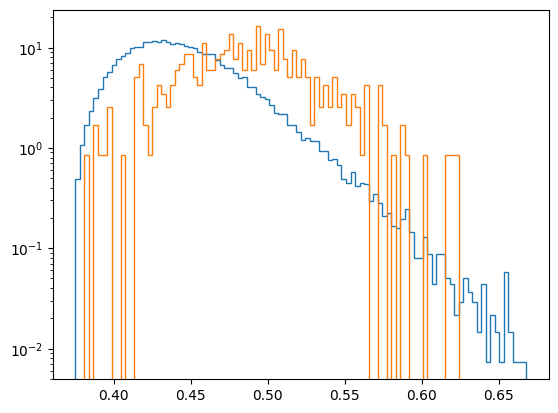

In [ ]:
plt.hist(df_iforest[df_iforest['particle'] == 'pr']['iforest_score'], bins=100, label='pr', log=True, density=True, histtype='step', range=(0.375, 0.668))
plt.hist(df_iforest[df_iforest['particle'] == 'ph']['iforest_score'], bins=100, label='ph', log=True, density=True, histtype='step', range=(0.375, 0.668))


In [ ]:
# KDE

In [ ]:
from sklearn.neighbors import KernelDensity

In [ ]:
num =47000
ch_emb = 6
num_ph = 400
print(f'part of data {num_ph/num}')
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
index = np.random.randint(0, len(embading_pr), num)
index_ph = np.random.randint(0, len(embading_photon), num_ph)
# with recos

#feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1), recos_pr[index]], axis=1)

#feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1), recos_photon[index_ph]], axis=1)

# without recos
feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1)], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1)], axis=1)

feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

label = np.concatenate([np.zeros(num), np.ones(num_ph)])

# shufle
shufle_index = np.random.permutation(len(feaches))
feaches = feaches[shufle_index]
label = label[shufle_index]

num_det_feaches = feaches[:,ch_emb]

print(feaches[:10], label[:10])

part of data 0.00851063829787234
pr (210315, 6) ph (210851, 6)
[[ 2.02569887e-01  3.52062076e-01 -1.01944661e+00  1.36310351e+00
   1.03550673e-01  1.02803397e+00  1.50000000e+01  5.87102911e-03]
 [ 1.72811604e+00  6.67437077e-01  8.32756281e-01 -9.10253346e-01
   1.83107138e-01  2.28093788e-01  8.00000000e+00  9.83920414e-04]
 [-3.31793427e-01  2.57853031e-01  8.53314936e-01 -4.22157049e-01
   1.08234835e+00  1.27239454e+00  1.20000000e+01  2.58577336e-03]
 [ 3.42081904e-01 -2.08956432e+00 -3.84841353e-01  4.73867744e-01
  -1.01573110e+00  1.18268418e+00  1.40000000e+01  1.59378012e-03]
 [ 8.88173580e-01  2.09860086e-01 -6.72657251e-01  1.83035463e-01
   6.71072721e-01 -9.13895249e-01  1.20000000e+01  4.28161211e-03]
 [ 2.16639042e+00  2.66503021e-02 -1.40878105e+00 -1.59441698e+00
   9.63510633e-01  1.24480598e-01  1.50000000e+01  9.20029765e-04]
 [ 7.58393705e-01 -1.18160772e+00 -2.38379277e-03  8.35139930e-01
   6.30963326e-01 -1.48021713e-01  1.10000000e+01  3.92144267e-03]
 [ 9.1

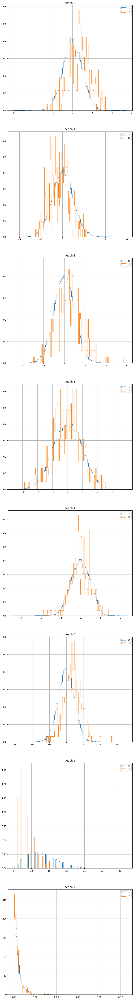

In [ ]:

fig, ax = plt.subplots(feaches.shape[1],1, figsize=(10, feaches.shape[1]*10))
for i in range(feaches.shape[1]):
    ax[i].hist(feaches[label == 0,i], bins=100, label=f'pr', histtype='step', density=True)
    ax[i].hist(feaches[label == 1,i], bins=100, label=f'ph', histtype='step', density=True)
    ax[i].legend()
    ax[i].set_title(f'feach {i}')
    ax[i].grid()
plt.show()



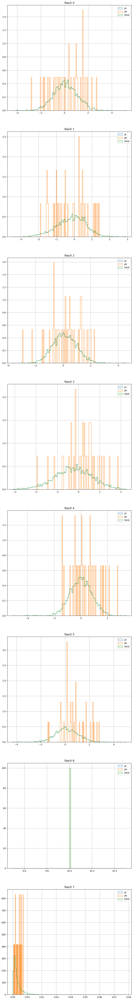

In [ ]:
N=10
fig, ax = plt.subplots(feaches.shape[1],1, figsize=(10, feaches.shape[1]*10))
for i in range(feaches.shape[1]):
    ax[i].hist(feaches[label == 0,i][num_det_feaches[label == 0] == N], bins=100, label=f'pr', histtype='step', density=True)
    ax[i].hist(feaches[label == 1,i][num_det_feaches[label == 1] == N], bins=100, label=f'ph', histtype='step', density=True)
    ax[i].hist(feaches[:,i][num_det_feaches == N], bins=100, label=f'total', histtype='step', density=True)
    ax[i].legend()
    ax[i].set_title(f'feach {i}')
    ax[i].grid()
plt.show()

In [ ]:
feaches_pr[feaches_pr[:,6] == N, 7].shape

(4095,)

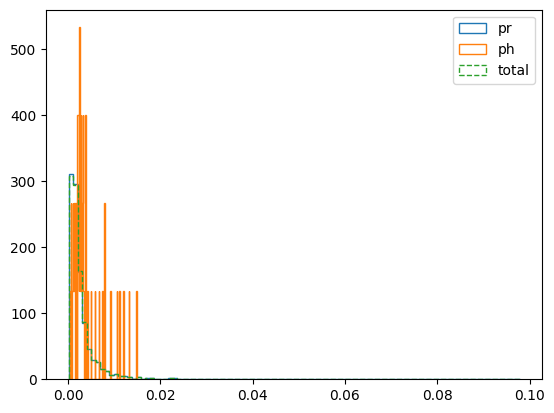

In [ ]:
N = 9
plt.hist(feaches_pr[feaches_pr[:,ch_emb] == N, 7], bins=100, label='pr', histtype='step', density=True)
plt.hist(feaches_photon[feaches_photon[:,ch_emb] == N, 7], bins=100, label='ph', histtype='step', density=True)
plt.hist(feaches[feaches[:,ch_emb] == N, 7], bins=100, label='total', histtype='step', density=True, linestyle='--')
plt.legend()
plt.show()

(4095, 8) (36, 8)


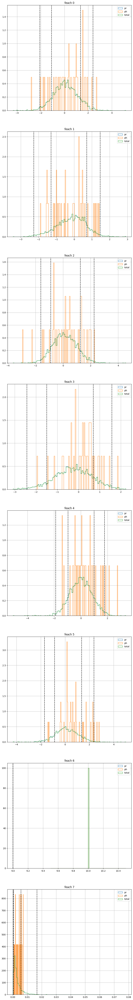

In [ ]:
# quantile
quan_list = [0.01, 0.1, 0.9, 0.99]
quantile_feaches = np.quantile(feaches[num_det_feaches == N], quan_list, axis=0)
N=10
fig, ax = plt.subplots(feaches.shape[1],1, figsize=(10, feaches.shape[1]*10))
for i in range(feaches.shape[1]):
    ax[i].hist(feaches[label == 0,i][num_det_feaches[label == 0] == N], bins=100, label=f'pr', histtype='step', density=True)
    ax[i].hist(feaches[label == 1,i][num_det_feaches[label == 1] == N], bins=100, label=f'ph', histtype='step', density=True)
    ax[i].hist(feaches[:,i][num_det_feaches == N], bins=100, label=f'total', histtype='step', density=True)
    ax[i].legend()
    for j in range(quantile_feaches.shape[0]):
        ax[i].axvline(quantile_feaches[j,i], color='k', linestyle='--', label=f'quan {quan_list[j]}')
    ax[i].set_title(f'feach {i}')
    
    ax[i].grid()
pr = feaches[label == 0,:][num_det_feaches[label == 0] == N]
ph = feaches[label == 1,:][num_det_feaches[label == 1] == N]
print(pr.shape, ph.shape)


In [ ]:
ch_emb= 6
X = feaches[:][num_det_feaches == N].copy()
X = np.concatenate([X[:,:ch_emb], X[:,ch_emb+1:]], axis=1)
print(X.shape)
# Лучше RobustScaler, чем StandardScaler, для задач с выбросами
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)
X_scaled
label_X = label[num_det_feaches == N]
print('pr',(label_X == 0).sum(), 'ph', (label_X == 1).sum())
# feaches = X_scaled

(4131, 7)
pr 4095 ph 36


-6.421288613981038 -7.100118406303867
0.6545787527641499 0.0


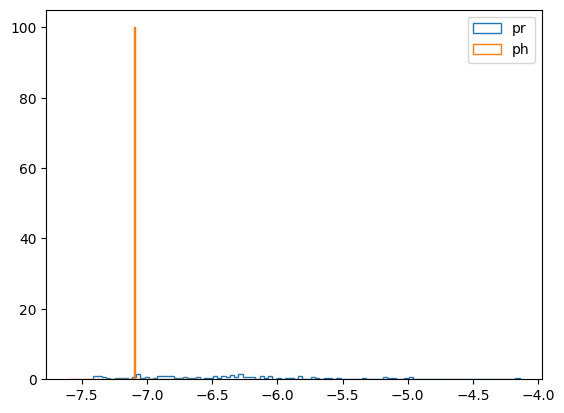

In [ ]:
# kde

bandwidth = 0.35

num=100
index = np.random.randint(0, len(X_scaled), num)
kde = KernelDensity(bandwidth=bandwidth).fit(X_scaled)


scores = kde.score_samples(X_scaled[index])
label_scores = label_X[index]

plt.hist(scores[label_scores == 0], bins=100, label='pr', histtype='step', density=True,)
plt.hist(scores[label_scores == 1], bins=100, label='ph', histtype='step', density=True,)
print(scores[label_scores == 0].mean(), scores[label_scores == 1].mean())
print(scores[label_scores == 0].std(), scores[label_scores == 1].std())
plt.legend()
plt.show()




-6.420877686646742 -7.145980514357419
0.6557217163877522 0.3187303447285529


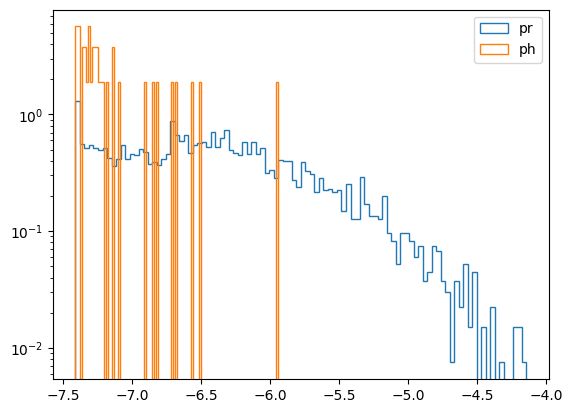

In [ ]:
scores_pr = kde.score_samples(X_scaled[label_X == 0])
scores_ph = kde.score_samples(X_scaled[label_X == 1])
print(scores_pr.mean(), scores_ph.mean())
print(scores_pr.std(), scores_ph.std())
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.legend()

-6.420877686646742 -7.145980514357419
0.6557217163877522 0.3187303447285529


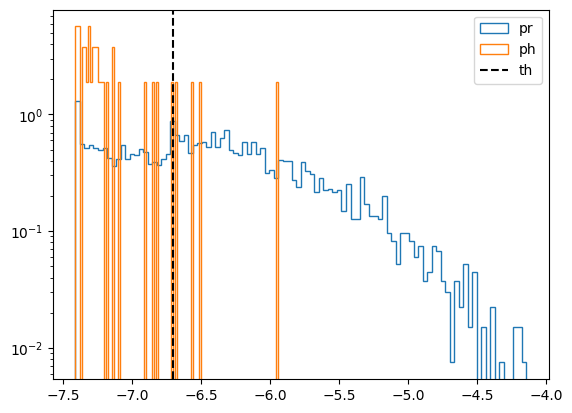

In [ ]:
th=-6.7
scores_pr = kde.score_samples(X_scaled[label_X == 0])
scores_ph = kde.score_samples(X_scaled[label_X == 1])
print(scores_pr.mean(), scores_ph.mean())
print(scores_pr.std(), scores_ph.std())
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.axvline(th, color='k', linestyle='--', label=f'th')
plt.legend()

In [ ]:
def show_del_by_score(pr, ph, use_ph=True, n_ph=1, density_ph = None, density_pr = None, th = 0.1):
    # pr_index= np.random.randint(0, pr.shape[0], size=5000)
    # ph_index= np.random.randint(0, ph.shape[0], size=5000)
    # pr = pr[pr_index]
    # ph = ph[ph_index]
    fig = plt.subplot()
    plt.hist(density_pr, bins=100, label='pr', histtype='step', density=True, log=True)
    plt.hist(density_ph, bins=100, label='ph', histtype='step', density=True, log=True)
    plt.axvline(th, color='k', linestyle='--', label=f'th')
    plt.legend()
    plt.show()
    fig, ax = plt.subplots(2,3, figsize=(12, 12))
    ax_1, ax_2, ax_3 = ax[0]
    reducer = umap.UMAP(n_components=2)
    if use_ph:
        manifold = reducer.fit(np.concatenate([pr, ph[::n_ph]], axis=0))
    else:
        manifold = reducer.fit(pr)
    X_pr = manifold.transform(pr)
    X_ph = manifold.transform(ph)

    X_all = np.vstack([X_pr, X_ph[::n_ph]])

    kde = gaussian_kde(X_all.T, )
    x_min, x_max = X_all[:, 0].min() - 1, X_all[:, 0].max() + 1
    y_min, y_max = X_all[:, 1].min() - 1, X_all[:, 1].max() + 1
    grid_x, grid_y = np.mgrid[x_min:x_max:100j, y_min:y_max:100j]
    density = kde(np.vstack([grid_x.ravel(), grid_y.ravel()]))
    density = density.reshape(grid_x.shape)
    cmap = plt.colormaps['PiYG']
    # (1,0) - плотность для всех точек
    im = ax[0, 2].pcolormesh(grid_x, grid_y, density, cmap=cmap)
    ax[0, 2].set_title('Density (all)')
    fig.colorbar(im, ax=ax[0, 2], label='Density')

    im = ax[1, 2].pcolormesh(grid_x, grid_y, density, cmap=cmap)
    ax[1, 2].set_title('Density (all)')
    fig.colorbar(im, ax=ax[1, 2], label='Density')

    ax_1, ax_2, ax_3 = ax[0]
    ax_1.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_2.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_3.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_1.legend()
    ax_2.legend()
    ax_3.legend()

    pr_index = density_pr<th
    ph_index = density_ph<th
    print(len(density_pr), len(density_ph))
    print(pr_index.sum(), ph_index.sum())
    print(len(X_pr[pr_index, 0]), len(X_ph[ph_index, 0]))
    ax_1, ax_2, ax_3 = ax[1]
    ax_1.scatter(X_pr[pr_index, 0], X_pr[pr_index, 1], s=0.5, alpha=0.3, label='pr')
    ax_2.scatter(X_ph[ph_index, 0], X_ph[ph_index, 1], s=0.5, alpha=0.3, label='ph')
    ax_3.scatter(X_pr[pr_index, 0], X_pr[pr_index, 1], s=0.5, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[ph_index, 0], X_ph[ph_index, 1], s=0.5, alpha=0.3, label='ph')
    
    # ax[1,1].hist(density_ph, bins=100, label='ph', histtype='step', density=True, log=True)
    # ax[1,1].hist(density_pr, bins=100, label='pr', histtype='step', density=True, log=True)
    # ax[1,1].legend()
    # ax[1,1].set_title('Density (ph and pr)')
    # ax[1,1].grid()

    plt.tight_layout()
    plt.show()

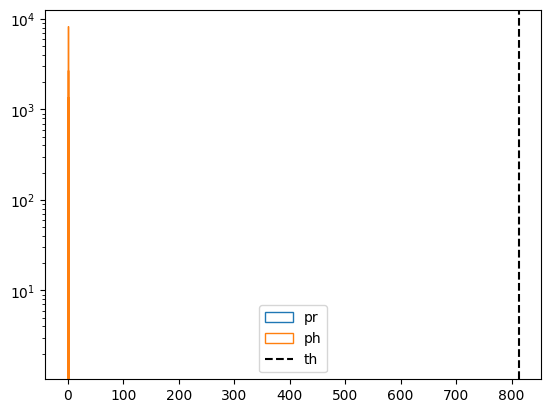

4095 36
4095 36
4095 36


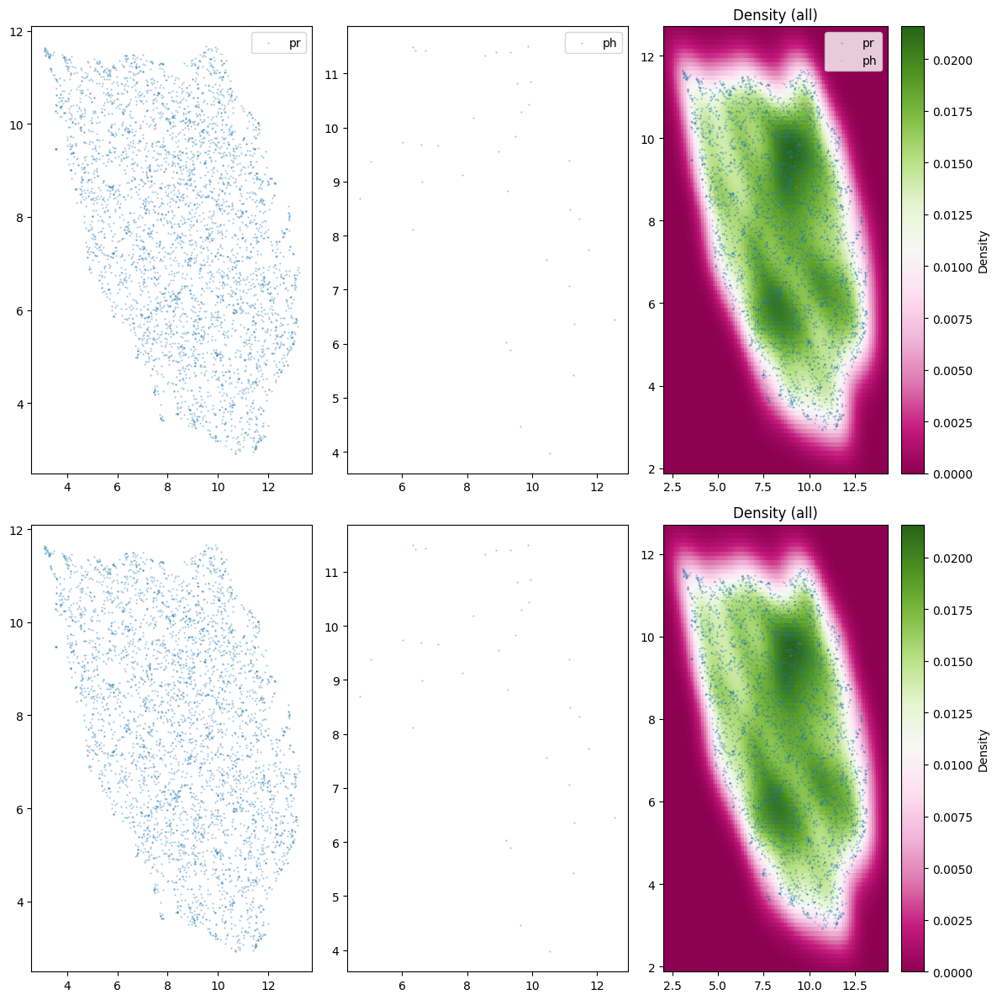

In [ ]:
th = -6.7
show_del_by_score(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=np.exp(scores_ph), density_pr=np.exp(scores_pr), th=np.exp(-th))

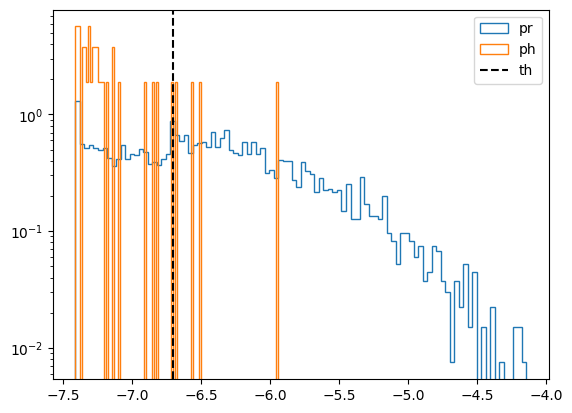

4095 36
1504 32
1504 32


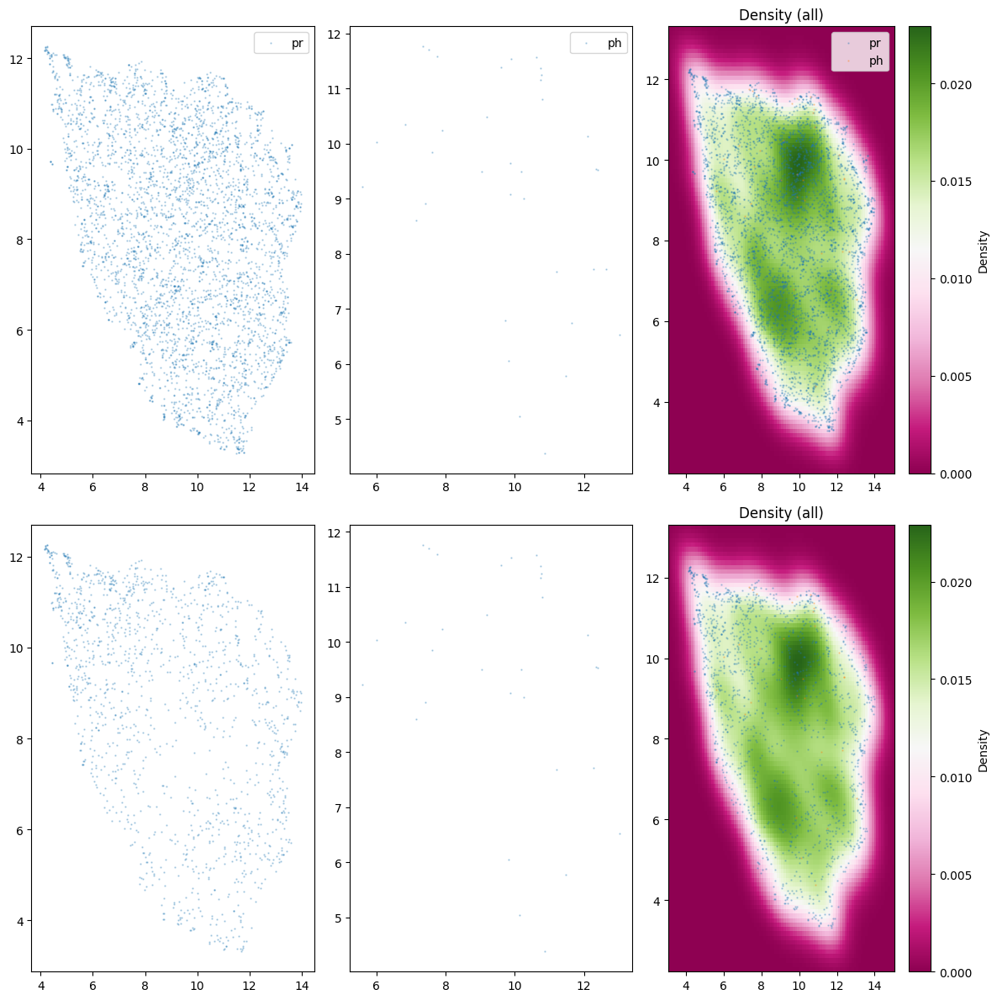

In [ ]:
show_del_by_score(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=scores_ph, density_pr=scores_pr, th=-6.7)

In [ ]:
# Полный прогоне KDE 

# Полный прогоне KDE 

In [ ]:
print(len(embading_pr), len(embading_photon))

210315 210851


In [ ]:
np.where(num_det_pr == N)[0].shape

(18391,)

part of data 0.01
pr (210315, 6) ph (210851, 6)
(10939, 7)
pr 10476 ph 463
-6.03973793402203 -6.976157430333174
0.7080336563713638 0.44979514717048596


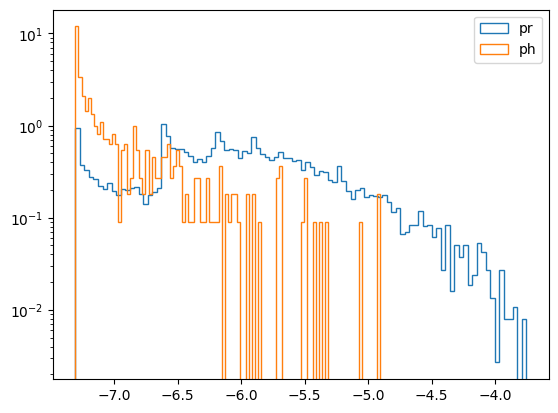

In [ ]:

num =200000
num_ph = 2000
N = 7
bandwidth = 0.3
print(f'part of data {num_ph/num}')
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
index = np.random.randint(0, len(embading_pr), num)
index_ph = np.random.randint(0, len(embading_photon), num_ph)
# with recos

index_pr_N_det = np.where(num_det_pr == N)[0]
index_ph_N_det = np.where(num_det_photon == N)[0]

# without recos
feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1)], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1)], axis=1)

feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

label = np.concatenate([np.zeros(num), np.ones(num_ph)])

# shufle
shufle_index = np.random.permutation(len(feaches))
feaches = feaches[shufle_index]
label = label[shufle_index]

num_det_feaches = feaches[:,ch_emb]



X = feaches[:][num_det_feaches == N].copy()
X = np.concatenate([X[:,:ch_emb], X[:,ch_emb+1:]], axis=1)
print(X.shape)
# Лучше RobustScaler, чем StandardScaler, для задач с выбросами
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)
X_scaled
label_X = label[num_det_feaches == N]
print('pr',(label_X == 0).sum(), 'ph', (label_X == 1).sum())


num=100
index = np.random.randint(0, len(X_scaled), num)
kde = KernelDensity(bandwidth=bandwidth).fit(X_scaled)


scores = kde.score_samples(X_scaled[index])
label_scores = label_X[index]

scores_pr = kde.score_samples(X_scaled[label_X == 0])
scores_ph = kde.score_samples(X_scaled[label_X == 1])
print(scores_pr.mean(), scores_ph.mean())
print(scores_pr.std(), scores_ph.std())
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.legend()

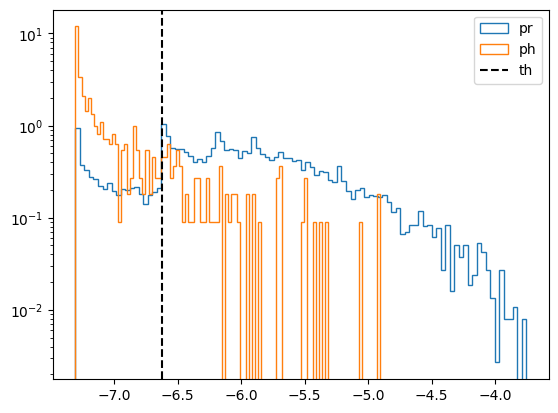

In [ ]:
th=-6.62
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.axvline(th, color='k', linestyle='--', label=f'th')
plt.legend()

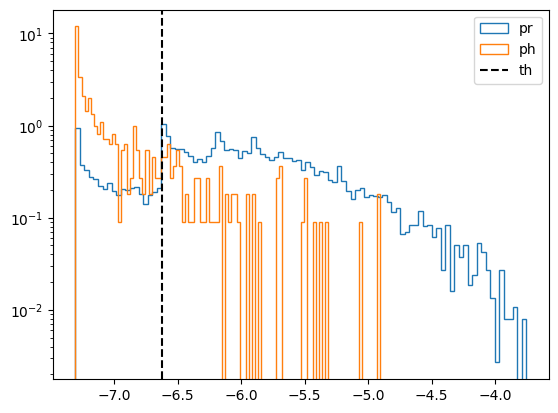

10476 463
1858 377
1858 377


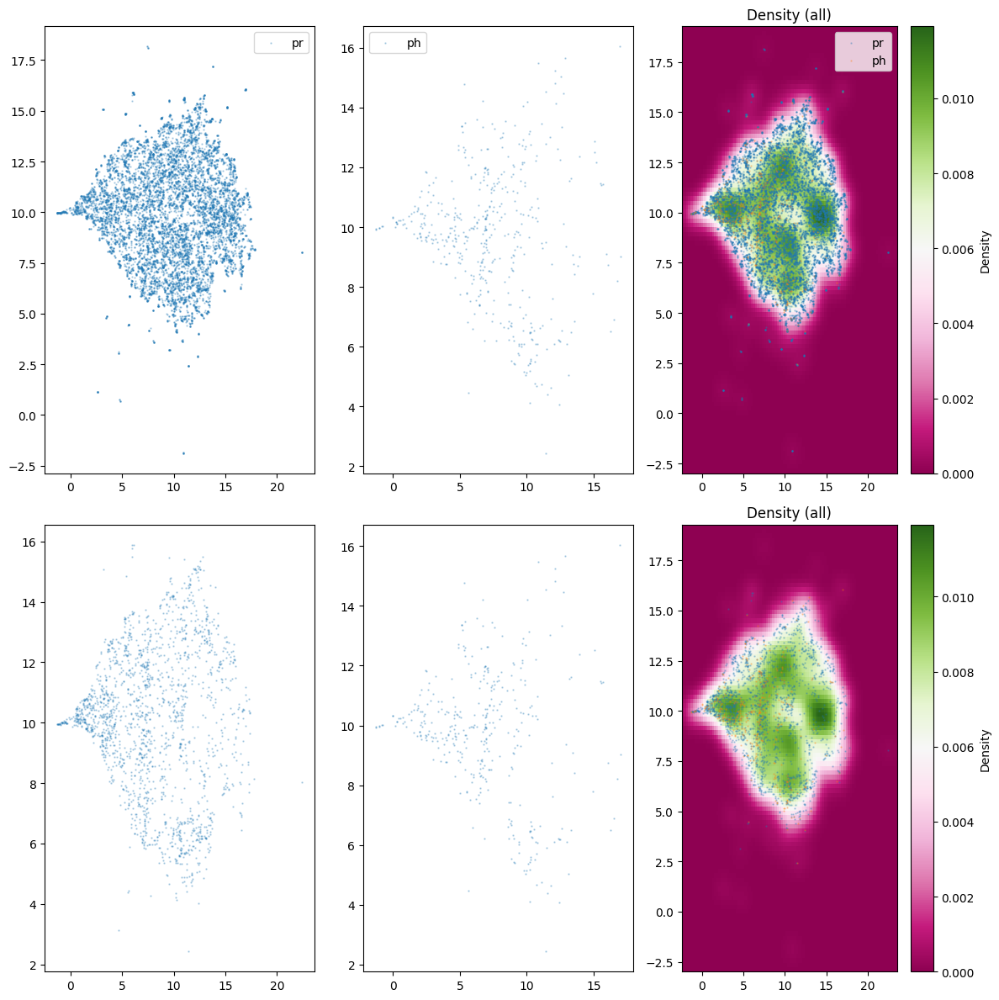

In [ ]:
show_del_by_score(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=scores_ph, density_pr=scores_pr, th=-6.62)

# 17.7% protons
# 81.4% photons

In [ ]:
th=-8.9
show_del_by_score(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=scores_ph, density_pr=scores_pr, th=th)

10376 458
2684 304
2684 304

10357 484
1449 212
1449 212

In [ ]:
# Проверка на востановление recos из латентного пространства
from catboost import CatBoostRegressor
latent_pr = embading_pr.copy()
latent_photon = embading_photon.copy()
print(latent_pr.shape, latent_photon.shape, recos_pr.shape, recos_photon.shape)

(210315, 6) (210851, 6) (210315, 15) (210851, 15)


In [ ]:
#test-train split
import sklearn
from sklearn.model_selection import train_test_split
latent_pr_train, latent_pr_test, recos_pr_train, recos_pr_test = train_test_split(latent_pr, recos_pr, test_size=0.2, random_state=42)
latent_photon_train, latent_photon_test, recos_photon_train, recos_photon_test = train_test_split(latent_photon, recos_photon, test_size=0.2, random_state=42)



In [ ]:
regressor = CatBoostRegressor(n_estimators=1000, learning_rate=0.05, depth=10, random_seed=42,
loss_function='MultiRMSE', eval_metric='MultiRMSE', early_stopping_rounds=20)
regressor.fit(latent_pr_train, recos_pr_train, eval_set=(latent_pr_test, recos_pr_test), use_best_model=True)




0:	learn: 3.8767503	test: 3.8668457	best: 3.8668457 (0)	total: 245ms	remaining: 4m 4s
1:	learn: 3.8764072	test: 3.8668856	best: 3.8668457 (0)	total: 509ms	remaining: 4m 13s
2:	learn: 3.8761535	test: 3.8668897	best: 3.8668457 (0)	total: 763ms	remaining: 4m 13s
3:	learn: 3.8758908	test: 3.8669248	best: 3.8668457 (0)	total: 997ms	remaining: 4m 8s
4:	learn: 3.8755514	test: 3.8669188	best: 3.8668457 (0)	total: 1.24s	remaining: 4m 7s
5:	learn: 3.8752395	test: 3.8669281	best: 3.8668457 (0)	total: 1.5s	remaining: 4m 8s
6:	learn: 3.8750008	test: 3.8669561	best: 3.8668457 (0)	total: 1.77s	remaining: 4m 11s
7:	learn: 3.8746971	test: 3.8669702	best: 3.8668457 (0)	total: 2.04s	remaining: 4m 13s
8:	learn: 3.8743731	test: 3.8670063	best: 3.8668457 (0)	total: 2.28s	remaining: 4m 10s
9:	learn: 3.8740308	test: 3.8670228	best: 3.8668457 (0)	total: 2.52s	remaining: 4m 9s
10:	learn: 3.8737628	test: 3.8670227	best: 3.8668457 (0)	total: 2.74s	remaining: 4m 6s
11:	learn: 3.8734312	test: 3.8670451	best: 3.8668

In [ ]:
regressor.

## ПРогон KDE с recos

part of data 0.01
pr (210315, 6) ph (210851, 6)
(202000, 23)





In [ ]:

num =200000
num_ph = 2000
N = 7
bandwidth = 0.41
print(f'part of data {num_ph/num}')
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
index = np.random.randint(0, len(embading_pr), num)
index_ph = np.random.randint(0, len(embading_photon), num_ph)
# with recos

feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1)], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1)], axis=1)

# add recos
feaches_pr = np.concatenate([feaches_pr, recos_pr[index]], axis=1)
feaches_photon = np.concatenate([feaches_photon, recos_photon[index_ph]], axis=1)


feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

label = np.concatenate([np.zeros(num), np.ones(num_ph)])

# shufle
shufle_index = np.random.permutation(len(feaches))
feaches = feaches[shufle_index]
label = label[shufle_index]

num_det_feaches = feaches[:,ch_emb]

print(feaches.shape)
fig, ax = plt.subplots(feaches.shape[1],1, figsize=(10, feaches.shape[1]*10))
for i in range(feaches.shape[1]):
    ax[i].hist(feaches[label == 0,i], bins=100, label=f'pr', histtype='step', density=True)
    ax[i].hist(feaches[label == 1,i], bins=100, label=f'ph', histtype='step', density=True)
    ax[i].legend()
    ax[i].set_title(f'feach {i}')
    ax[i].grid()
plt.show()

part of data 0.01
pr (210315, 8) ph (210851, 8)
[[ 4.34671849e-01  4.49277103e-01  2.28105724e-01  5.41433513e-01
  -1.10380065e+00 -1.11490464e+00 -8.64692450e-01 -1.02637076e+00
   9.00000000e+00  6.66710315e-03  1.38128757e+00  6.84225783e-02
  -1.02817282e-01  7.56021500e-01]
 [-5.85101843e-01  1.77080691e+00  8.62918913e-01 -4.14451182e-01
   1.68913400e+00  1.31564379e+00 -7.44193077e-01  1.19321674e-01
   1.00000000e+01  6.87978324e-03 -7.46476114e-01 -1.29246199e+00
   1.16859007e+00  8.00965905e-01]
 [-2.49369711e-01  8.18214774e-01 -3.97974439e-03  3.63665879e-01
   1.54659307e+00  3.77776682e-01 -1.55828297e+00  9.90129590e-01
   1.10000000e+01  4.79980884e-03  8.86704445e-01  2.63838738e-01
  -4.11055982e-01 -3.48720312e-01]
 [-1.95486927e+00 -1.07884419e+00 -1.34793437e+00  2.75565922e-01
   7.06481695e-01 -1.16176713e+00  1.46287382e-01 -1.04862607e+00
   1.70000000e+01  7.17344414e-03  8.79210755e-02 -7.15842903e-01
   1.56210721e+00  1.28701925e+00]
 [ 1.71147394e+00  3

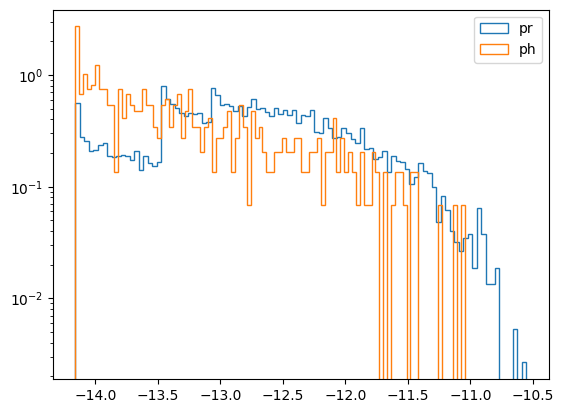

In [ ]:
num =200000
num_ph = 2000
N = 7
recos_last = -4
bandwidth = 0.58
print(f'part of data {num_ph/num}')
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
index = np.random.randint(0, len(embading_pr), num)
index_ph = np.random.randint(0, len(embading_photon), num_ph)
# with recos

index_pr_N_det = np.where(num_det_pr == N)[0]
index_ph_N_det = np.where(num_det_photon == N)[0]

# without recos
feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1)], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1)], axis=1)

# add recos
feaches_pr = np.concatenate([feaches_pr, recos_pr[index, :-recos_last]], axis=1)
feaches_photon = np.concatenate([feaches_photon, recos_photon[index_ph, :-recos_last]], axis=1)



feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

label = np.concatenate([np.zeros(num), np.ones(num_ph)])

# shufle
shufle_index = np.random.permutation(len(feaches))
feaches = feaches[shufle_index]
label = label[shufle_index]

num_det_feaches = feaches[:,8]

print(feaches[:10], label[:10])


X = feaches[:][num_det_feaches == N].copy()
X = np.concatenate([X[:,:8], X[:,9:]], axis=1)
print(X.shape)
# Лучше RobustScaler, чем StandardScaler, для задач с выбросами
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)
X_scaled
label_X = label[num_det_feaches == N]
print('pr',(label_X == 0).sum(), 'ph', (label_X == 1).sum())


num=100
index = np.random.randint(0, len(X_scaled), num)
kde = KernelDensity(bandwidth=bandwidth).fit(X_scaled)


scores = kde.score_samples(X_scaled[index])
label_scores = label_X[index]

scores_pr = kde.score_samples(X_scaled[label_X == 0])
scores_ph = kde.score_samples(X_scaled[label_X == 1])
print(scores_pr.mean(), scores_ph.mean())
print(scores_pr.std(), scores_ph.std())
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.legend()

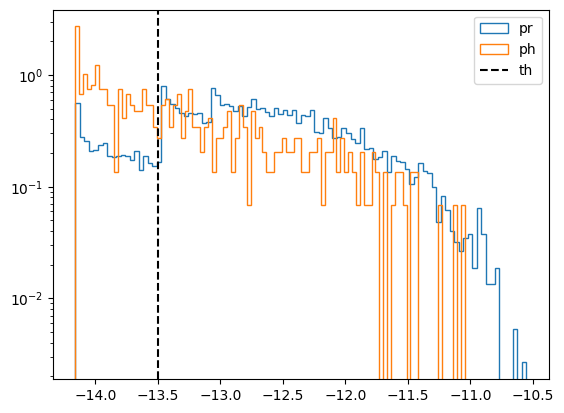

10407 472
1509 227
1509 227


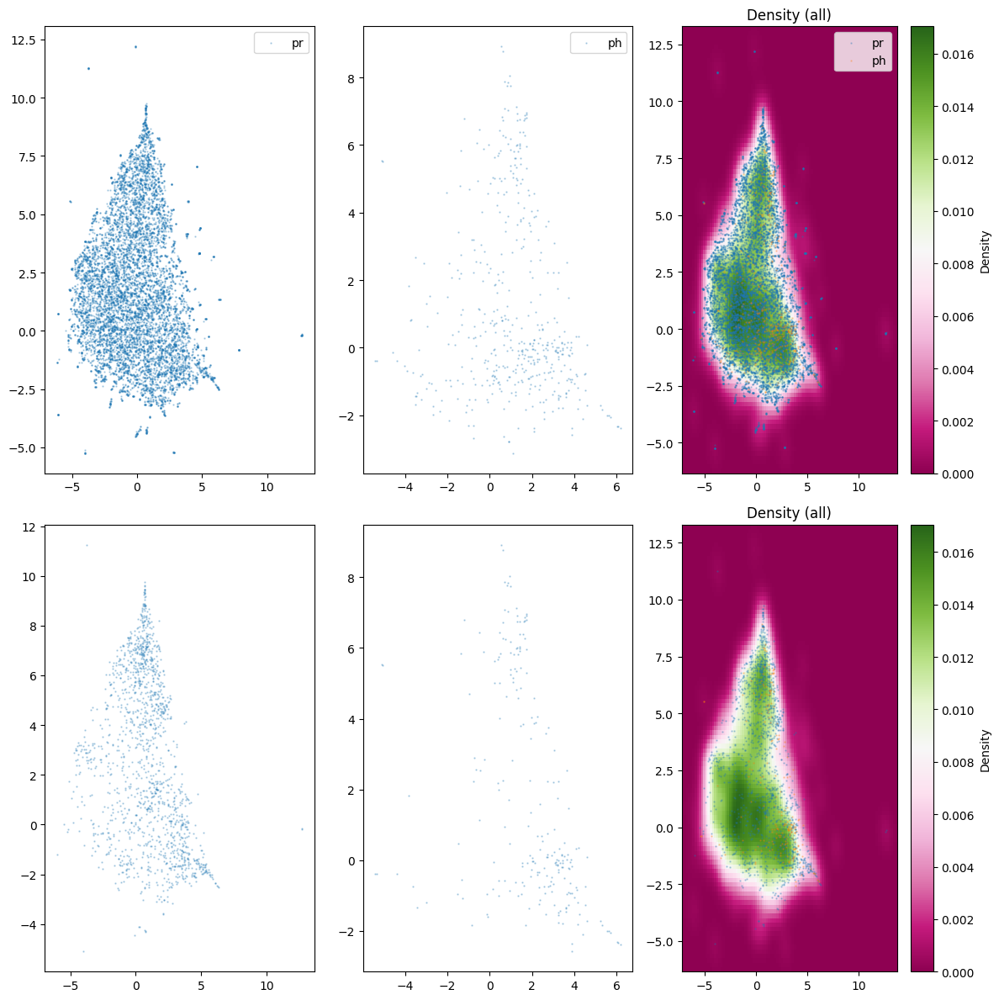

In [ ]:
th=-13.5
show_del_by_score(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=scores_ph, density_pr=scores_pr, th=th)

In [ ]:
def show_del_by_score_only_KDE_MAP(pr, ph, use_ph=True, n_ph=1, density_ph = None, density_pr = None, th = 0.1):
    # pr_index= np.random.randint(0, pr.shape[0], size=5000)
    # ph_index= np.random.randint(0, ph.shape[0], size=5000)
    # pr = pr[pr_index]
    # ph = ph[ph_index]
    fig = plt.subplot()
    plt.hist(density_pr, bins=100, label='pr', histtype='step', density=True, log=True)
    plt.hist(density_ph, bins=100, label='ph', histtype='step', density=True, log=True)
    plt.axvline(th, color='k', linestyle='--', label=f'th')
    plt.legend()
    plt.title('Density (pr and ph)')
    plt.xlabel('log probability')
    plt.ylabel('log density')
    plt.show()
    fig, ax = plt.subplots(1,2, figsize=(12, 12))
    ax_3 = ax[0]
    reducer = umap.UMAP(n_components=2)
    if use_ph:
        manifold = reducer.fit(np.concatenate([pr, ph[::n_ph]], axis=0))
    else:
        manifold = reducer.fit(pr)
    X_pr = manifold.transform(pr)
    X_ph = manifold.transform(ph)

    X_all = np.vstack([X_pr, X_ph[::n_ph]])

    kde = gaussian_kde(X_all.T, )
    x_min, x_max = X_all[:, 0].min() - 1, X_all[:, 0].max() + 1
    y_min, y_max = X_all[:, 1].min() - 1, X_all[:, 1].max() + 1
    grid_x, grid_y = np.mgrid[x_min:x_max:100j, y_min:y_max:100j]
    density = kde(np.vstack([grid_x.ravel(), grid_y.ravel()]))
    density = density.reshape(grid_x.shape)
    cmap = plt.colormaps['PiYG']
    # (1,0) - плотность для всех точек
    im = ax[0].pcolormesh(grid_x, grid_y, density, cmap=cmap)
    ax[0].set_title('All Data')
    fig.colorbar(im, ax=ax[0], label='Density')

    im = ax[1].pcolormesh(grid_x, grid_y, density, cmap=cmap)
    ax[1].set_title('Anomaly Data')
    fig.colorbar(im, ax=ax[1], label='Density')

    ax_3 = ax[0]
    ax_3.scatter(X_pr[:, 0], X_pr[:, 1], s=1, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[:, 0], X_ph[:, 1], s=1, alpha=0.3, label='ph')
    ax_1.legend()
    ax_2.legend()
    ax_3.legend()

    pr_index = density_pr<th
    ph_index = density_ph<th
    print(len(density_pr), len(density_ph))
    print(pr_index.sum(), ph_index.sum())
    print(len(X_pr[pr_index, 0]), len(X_ph[ph_index, 0]))
    ax_3 = ax[1]
    ax_3.scatter(X_pr[pr_index, 0], X_pr[pr_index, 1], s=3, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[ph_index, 0], X_ph[ph_index, 1], s=3, alpha=0.3, label='ph')
    
    # ax[1,1].hist(density_ph, bins=100, label='ph', histtype='step', density=True, log=True)
    # ax[1,1].hist(density_pr, bins=100, label='pr', histtype='step', density=True, log=True)
    # ax[1,1].legend()
    # ax[1,1].set_title('Density (ph and pr)')
    # ax[1,1].grid()

    plt.tight_layout()
    plt.show()

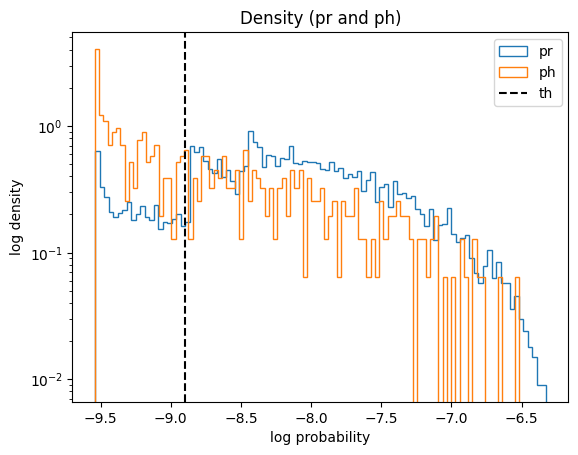

10358 514
1516 257
1516 257


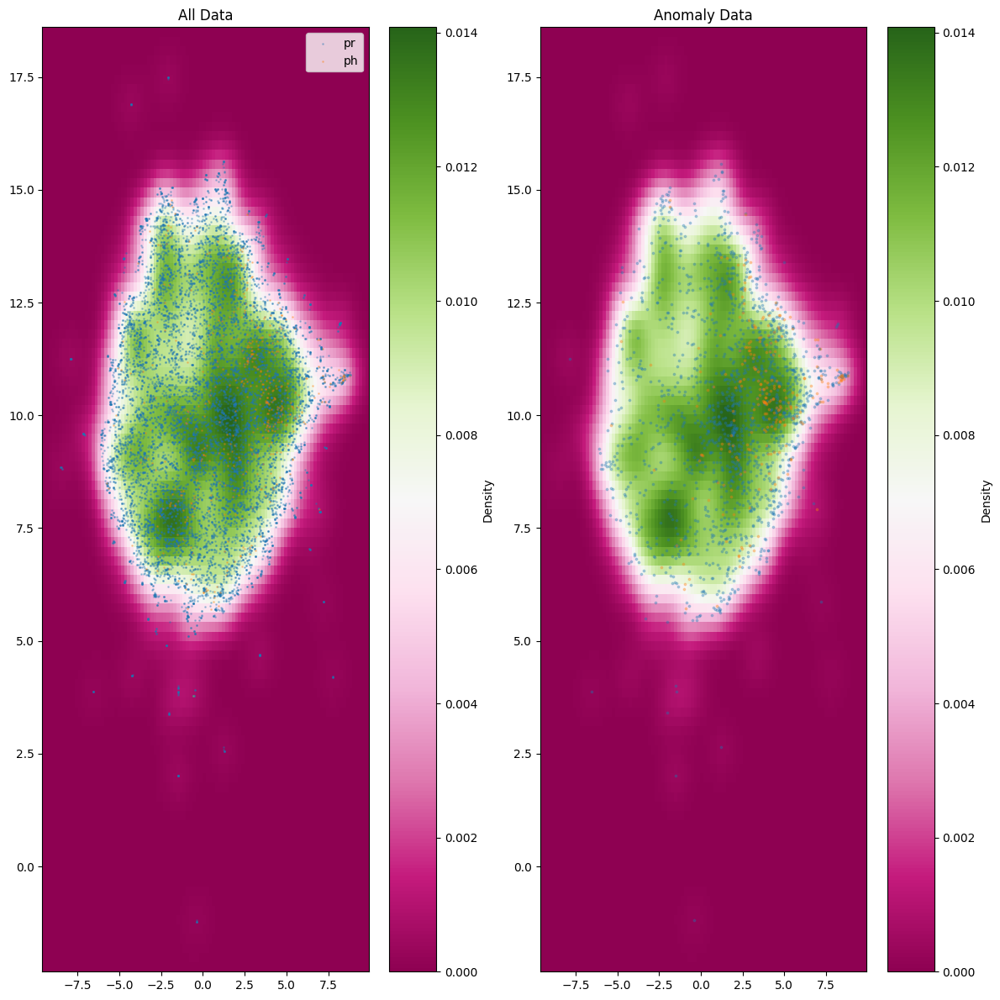

In [ ]:
show_del_by_score_only_KDE_MAP(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=scores_ph, density_pr=scores_pr, th=th)

Было 
```
10440 485
1540 263
1540 263
```

СТало
```
10407 472
1509 227
1509 227
```

## по бинам анализ

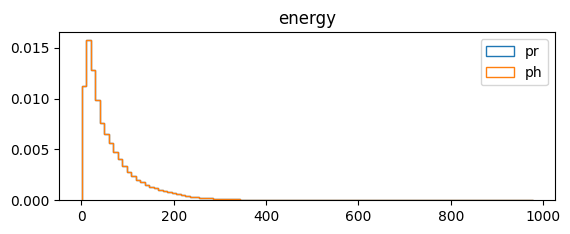

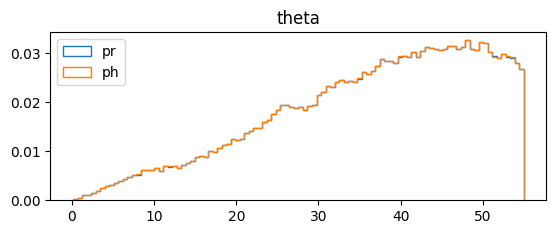

In [ ]:
# plt.subplots(2,1, figsize=(10, 10))
plt.subplot(2,1,1)
plt.hist(recos_norming_pr[:,3], bins=100, label='pr', histtype='step', density=True)
plt.hist(recos_norming_photon[:,3], bins=100, label='ph', histtype='step', density=True)
plt.title('energy')
plt.legend()
plt.show()
plt.subplot(2,1,2)
plt.hist(recos_norming_pr[:,0], bins=100, label='pr', histtype='step', density=True)
plt.hist(recos_norming_photon[:,0], bins=100, label='ph', histtype='step', density=True)
plt.title('theta')
plt.legend()
plt.show()


[     0  30045  60090  90135 120180 150225 180270 210314] 8


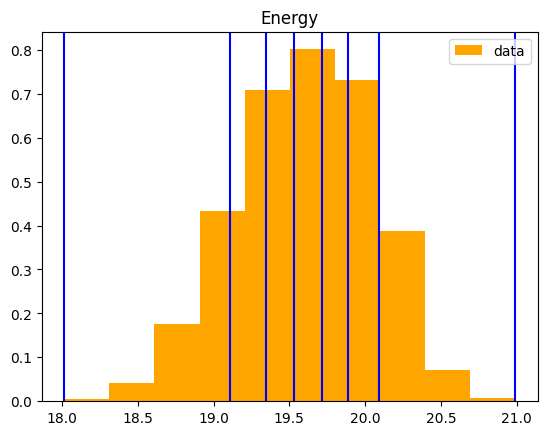

данных в одном бине 30045.0


In [ ]:
Energy_pr = np.log10(recos_norming_pr[:,3])+18
Energy_photon = np.log10(recos_norming_photon[:,3])+18
indices_pr_E = np.argsort(recos_norming_pr[:,3])
indices_photon_E = np.argsort(recos_norming_photon[:,3])
num_bins = 7

indices_bin_E = np.linspace(0, len(indices_pr_E), num_bins,endpoint=False).astype(int)
indices_bin_E = np.append(indices_bin_E, len(indices_pr_E)-1)
print(indices_bin_E, len(indices_bin_E))

plt.hist(Energy_pr, density=True, label='data', color='orange')
# plt.hist(Energy_photon, density=True, label='photon')
for i in range(num_bins+1):
    v = indices_pr_E[indices_bin_E[i]]
    # plt.axvline(Energy_pr[v], color='red')
    plt.axvline(Energy_photon[v], color='blue')
plt.legend()
plt.title('Energy')
plt.show()

print(f'данных в одном бине {len(indices_pr_E)/num_bins}')

-0.44057262 -0.18435791


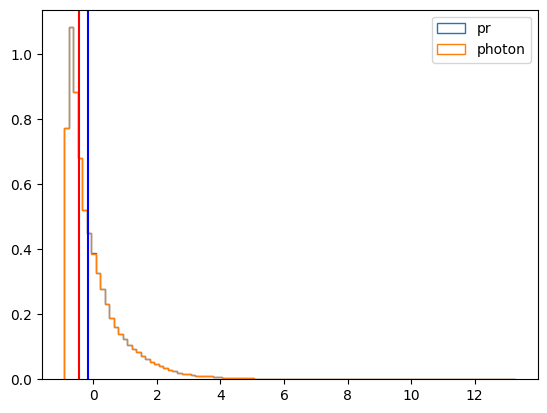

In [ ]:
n_bin = 3

v_min = indices_pr_E[indices_bin_E[n_bin]]
v_max = indices_pr_E[indices_bin_E[n_bin+1]]

E_min = recos_norming_pr[:,3][v_min]
E_max = recos_norming_pr[:,3][v_max]

norm_E_min = (E_min  - mean_recos[3])/std_recos[3]
norm_E_max = (E_max  - mean_recos[3])/std_recos[3]

print(norm_E_min, norm_E_max)



plt.hist(recos_pr[:,3], bins=100, label='pr', histtype='step', density=True)
plt.hist(recos_photon[:,3], bins=100, label='photon', histtype='step', density=True)
plt.axvline(norm_E_min, color='red')
plt.axvline(norm_E_max, color='blue')
plt.legend()
plt.show()

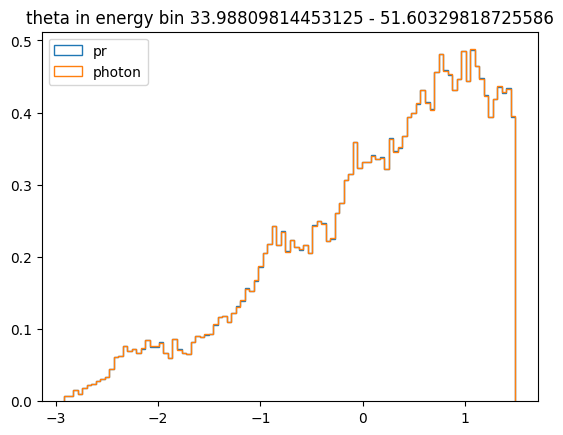

In [ ]:
indexby_ener_pr = np.where(np.logical_and(recos_pr[:,3] > norm_E_min, recos_pr[:,3] < norm_E_max))[0]
indexby_ener_photon = np.where(np.logical_and(recos_photon[:,3] > norm_E_min, recos_photon[:,3] < norm_E_max))[0]

plt.hist(recos_pr[indexby_ener_pr,0], bins=100, label='pr', histtype='step', density=True)
plt.hist(recos_photon[indexby_ener_photon,0], bins=100, label='photon', histtype='step', density=True)
plt.legend()
plt.title(f'theta in energy bin {E_min} - {E_max}')
plt.show()





In [ ]:
recos_pr[indexby_ener_pr,0].shape

(30044,)

[    0  4292  8584 12876 17168 21460 25752 30043] 8


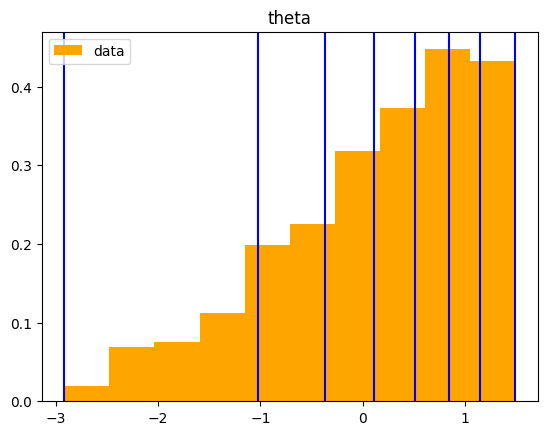

данных в одном бине 4292.0


In [ ]:
indices_pr_theta = np.argsort(recos_pr[indexby_ener_pr,0])
indices_photon_theta = np.argsort(recos_photon[indexby_ener_photon,0])
num_bins = 7

indices_bin_theta = np.linspace(0, len(recos_pr[indexby_ener_pr,0]), num_bins,endpoint=False).astype(int)
indices_bin_theta = np.append(indices_bin_theta, len(recos_pr[indexby_ener_pr,0])-1)
print(indices_bin_theta, len(indices_bin_theta))

plt.hist(recos_pr[indexby_ener_pr,0], density=True, label='data', color='orange')
# plt.hist(Energy_photon, density=True, label='photon')
for i in range(num_bins+1):
    v = indices_pr_theta[indices_bin_theta[i]]
    # plt.axvline(Energy_pr[v], color='red')
    plt.axvline(recos_pr[indexby_ener_pr,0][v], color='blue')
plt.legend()
plt.title('theta')
plt.show()

print(f'данных в одном бине {len(indices_pr_theta)/num_bins}')

-0.44057262 -0.18435791 0.10912752 0.50777656


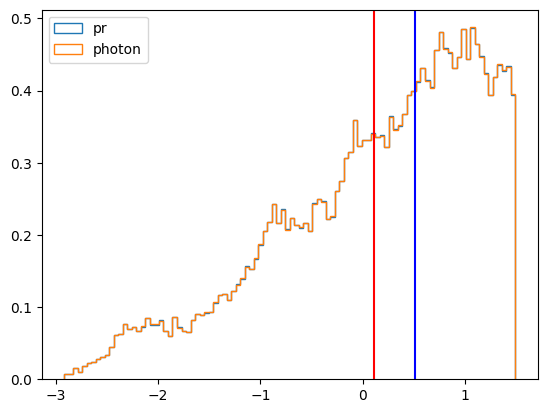

In [ ]:
n_bin_theta = 3

v_min = indices_pr_theta[indices_bin_theta[n_bin_theta]]
v_max = indices_pr_theta[indices_bin_theta[n_bin_theta+1]]

theta_min = recos_pr[indexby_ener_pr,0][v_min]
theta_max = recos_pr[indexby_ener_pr,0][v_max]

norm_theta_min = theta_min#(theta_min  - mean_recos[0])/std_recos[0]
norm_theta_max = theta_max#(theta_max  - mean_recos[0])/std_recos[0]

print(norm_E_min, norm_E_max, norm_theta_min, norm_theta_max)


plt.hist(recos_pr[indexby_ener_pr,0], bins=100, label='pr', histtype='step', density=True)
plt.hist(recos_photon[indexby_ener_photon,0], bins=100, label='photon', histtype='step', density=True)
plt.axvline(norm_theta_min, color='red')
plt.axvline(norm_theta_max, color='blue')
plt.legend()
plt.show()

(210315, 15) (30044,) (4291,)


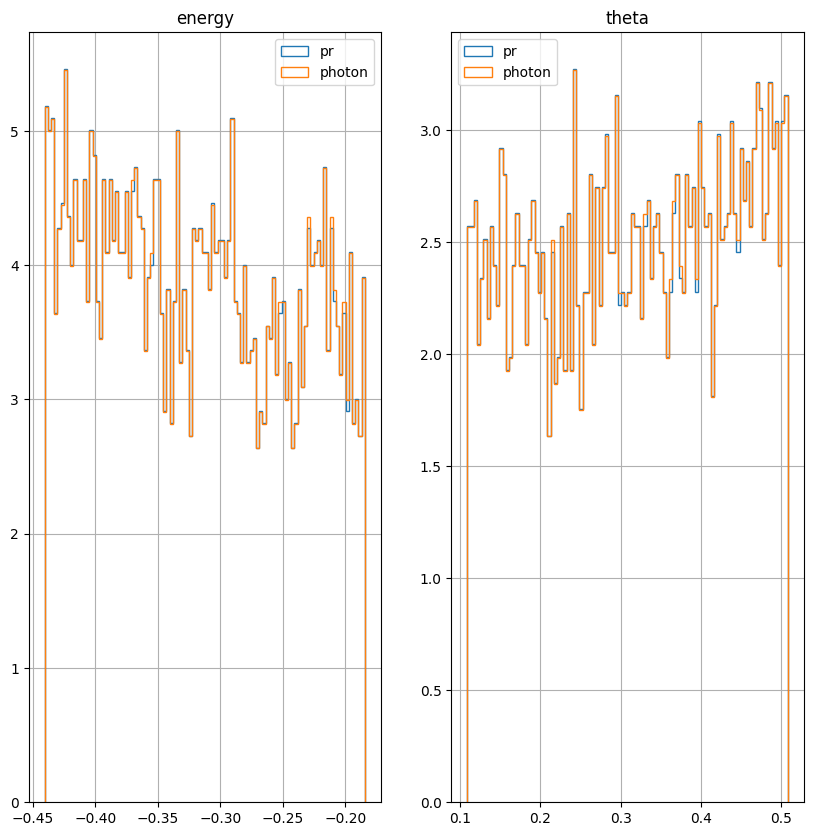

(4291,) (4299,)
0.10917559 0.5077444 0.10912752 0.50777656


In [ ]:
index_for_2_bins_pr = np.where(np.logical_and(recos_pr[indexby_ener_pr,0] > norm_theta_min, recos_pr[indexby_ener_pr,0] < norm_theta_max))[0]
index_for_2_bins_photon = np.where(np.logical_and(recos_photon[indexby_ener_photon,0] > norm_theta_min, recos_photon[indexby_ener_photon,0] < norm_theta_max))[0]

index_for_2_bins_pr = indexby_ener_pr[index_for_2_bins_pr]
index_for_2_bins_photon = indexby_ener_photon[index_for_2_bins_photon]
print(recos_pr.shape, indexby_ener_pr.shape, index_for_2_bins_pr.shape)
fig, ax = plt.subplots(1,2, figsize=(10, 10))
ax[0].hist(recos_pr[index_for_2_bins_pr,3], bins=100, label='pr', histtype='step', density=True)
ax[0].hist(recos_photon[index_for_2_bins_photon,3], bins=100, label='photon', histtype='step', density=True)


ax[1].hist(recos_pr[index_for_2_bins_pr,0], bins=100, label='pr', histtype='step', density=True)
ax[1].hist(recos_photon[index_for_2_bins_photon,0], bins=100, label='photon', histtype='step', density=True)

ax[0].legend()
ax[1].legend()

ax[0].set_title('energy')
ax[1].set_title('theta')
ax[0].grid()
ax[1].grid()
plt.show()
print(recos_pr[index_for_2_bins_pr,0].shape, recos_photon[index_for_2_bins_photon,0].shape)
print(recos_pr[index_for_2_bins_pr,0].min(), recos_pr[index_for_2_bins_pr,0].max(), norm_theta_min, norm_theta_max)

In [ ]:
# по бинам анализ


N = 10
recos_last = -4
bandwidth = 0.58
part = 0.1
print(f'part of data {part}')
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
# cut by energy bin and theta bin
index = index_for_2_bins_pr.copy()
index_ph = index_for_2_bins_photon.copy()
index_ph = np.random.choice(index_ph, int(len(index_ph)*part))
print('index_ph', index_ph.shape, 'index', index.shape)

# without recos
feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1)], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1)], axis=1)

# add recos
feaches_pr = np.concatenate([feaches_pr, recos_pr[index, :-recos_last]], axis=1)
feaches_photon = np.concatenate([feaches_photon, recos_photon[index_ph, :-recos_last]], axis=1)


print('feaches_pr', feaches_pr.shape, 'feaches_photon', feaches_photon.shape)

print('with detecor constant',np.sum(feaches_pr[:,8] == N), np.sum(feaches_photon[:,8] == N))


part of data 0.1
pr (210315, 8) ph (210851, 8)
index_ph (429,) index (4291,)
feaches_pr (4291, 14) feaches_photon (429, 14)
with detecor constant 397 35


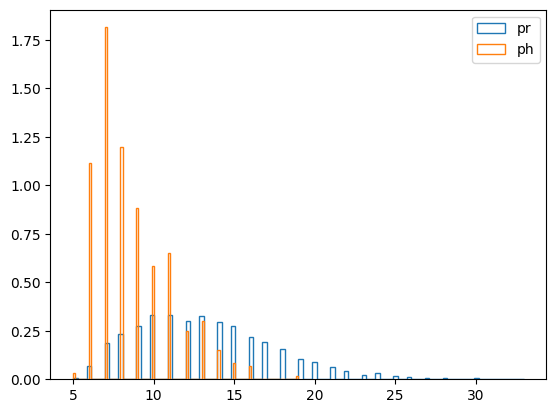

((2123,), (4291, 14), (429, 14))

In [ ]:
plt.hist(feaches_pr[:,8], bins=100, label='pr', histtype='step', density=True)
plt.hist(feaches_photon[:,8], bins=100, label='ph', histtype='step', density=True)
plt.legend()
plt.show()
num_det_feaches.shape, feaches_pr.shape, feaches_photon.shape

[[ 2.82276899e-01 -3.06957185e-01  6.13448441e-01 -6.10881150e-01
   1.27034798e-01 -1.07521743e-01 -1.22371924e+00  4.84812647e-01
   1.30000000e+01  7.11033773e-03  4.46862698e-01 -8.30664784e-02
  -3.45073342e-01 -4.20215279e-01]
 [-7.29734182e-01 -1.05972745e-01  8.98605883e-01  1.17789829e+00
   1.05351675e+00 -8.58903468e-01  5.37993386e-02  1.40717298e-01
   1.70000000e+01  9.28837340e-03  2.28627563e-01 -1.34669805e+00
  -1.40255122e-02 -1.85934573e-01]
 [-1.24646568e+00 -6.38287067e-01  1.15432358e+00 -9.88465995e-02
   9.22059536e-01 -3.05995643e-01  6.69436514e-01 -1.00423253e+00
   1.80000000e+01  1.34291090e-02  1.55015677e-01 -8.61243129e-01
  -2.97209501e-01 -4.23903883e-01]
 [ 8.58165979e-01  3.65336448e-01 -2.95471728e-01 -2.28258297e-01
  -1.03493667e+00 -1.38607574e+00 -6.24120712e-01 -8.89965296e-01
   1.00000000e+01  2.86129210e-03  2.94477820e-01 -5.17341018e-01
  -2.23230749e-01 -3.47735614e-01]
 [ 9.60003495e-01 -5.12816787e-01 -1.58817935e+00  3.67598057e-01
  

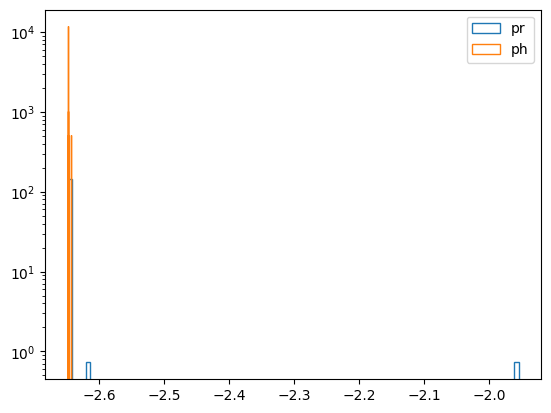

In [ ]:
bandwidth = 0.3
feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

label = np.concatenate([np.zeros(len(feaches_pr)), np.ones(len(feaches_photon))])

# # shufle
shufle_index = np.random.permutation(len(feaches))
feaches = feaches[shufle_index]
label = label[shufle_index]

num_det_feaches = feaches[:,8]

print(feaches[:10], label[:10])


# X = feaches[:][num_det_feaches == N].copy()
X = np.concatenate([X[:,:8], X[:,9:]], axis=1)
print(X.shape)
# Лучше RobustScaler, чем StandardScaler, для задач с выбросами
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)
X_scaled
label_X = label[num_det_feaches == N]
print('pr',(label_X == 0).sum(), 'ph', (label_X == 1).sum())


num=100
index = np.random.randint(0, len(X_scaled), num)
kde = KernelDensity(bandwidth=bandwidth).fit(X_scaled)


scores = kde.score_samples(X_scaled[index])
label_scores = label_X[index]

scores_pr = kde.score_samples(X_scaled[label_X == 0])
scores_ph = kde.score_samples(X_scaled[label_X == 1])
print(scores_pr.mean(), scores_ph.mean())
print(scores_pr.std(), scores_ph.std())
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.legend()